# Novelty metrics: every score each latent model offers

The awareness layer's first question is whether a window of movement is *unfamiliar*. The ankle paper answers it with
Local Outlier Factor (LOF) on an autoencoder's latent space: a window whose neighbourhood in the latent is sparser than
its neighbours' is scored as unfamiliar. This notebook scores every latent model trained so far (the plain, sparse and Gaussian-NLL
autoencoders and the VAE grid) and asks how well each one flags movement it never saw, on people it never saw: with
LOF, and from section 7 with every score native to each model family (the VAE's KL, decoder likelihood and posterior
uncertainty, the sparse model's out-of-range units, Mahalanobis distance). It picks up new runs and new scores automatically
(section 10).

**What counts as familiar.** Every model was trained on the four ID-safe tasks (normal, incline and weighted walking,
stairs) of 14 participants. On the four **test participants** (BT07, BT15, BT19, BT22), those four tasks are
*familiar*; the other 22 tasks are *unfamiliar*: 18 OOD-safe tasks (moment-estimator territory) and 4 OOD-dangerous
ones (ball toss, step-ups, tug of war, sit-to-stand).

**Protocol, fixed before any model was scored** (`_novelty_scores.py`):

| step | rule |
|---|---|
| fit and calibrate | each run's exported training windows (20,000, ID-safe tasks, training participants), split 75 / 25 with a fixed seed: the score is fitted on the first part, its threshold set on the second |
| threshold | the 99.5th percentile of the calibration scores (the ankle paper's rule) |
| test windows | in-task windows of the test participants that every model exported (those with 3 s of clean history, so 1 s and 3 s models are scored on the same windows) |
| filter | the ankle paper's causal median over the last 0.5 s of the same recording, applied before the threshold |
| primary metric | AUROC, unfamiliar against familiar windows (per-window scores, threshold-free) |
| at the threshold | share of unfamiliar and OOD-dangerous windows flagged, and the false-alarm rate on familiar windows |

Scores compared: **LOF on the raw latent** (the ankle paper's score, k = 20, from `ml/common/models/autoencoder.py`),
**LOF on the standardized latent** (each unit scaled by its training mean and SD, so a block of large co-firing units
cannot dominate the distances), and **reconstruction error**, the paper's rejected score, as a reference. Every number
is a mean over three seeds unless stated. Section 6 moves the threshold and the latent's dimensionality to the
validation participants, so the test participants are scored once.

## Findings at a glance

- **The full comparison (section 9): seven model types on four inputs.** 3 s raw is the best input for every model type,
  and the spectral features hurt everywhere; the best detector is the LSTM-VAE on 3 s raw (test AUROC 0.963, 0.993 for
  OOD-dangerous tasks; every dangerous movement flagged, half at its first window, at 6% familiar false switches; 4 to 6% for every
  3 s raw model).
  The spectral features make every architecture learn the same latent (linear CKA 0.68 against 0.37 for raw inputs),
  and they set the KL's direction: downward on raw input, upward with them. LOF on the latent is the best score on 23 of
  the 28 (model type, input) set-ups.
- **The TCN-VAE (notebook 08) ties the plain AE and the Transformer VAE on 3 s raw** (0.950, behind the LSTM-VAE's 0.963)
  and ranks the OOD-dangerous tasks best of any model (0.995), flagging every dangerous movement, half at its first window.

*The bullets below were found on the first two inputs (1 s raw and 3 s + spectral), before the 1 s + spectral and
3 s raw inputs and the sequence VAEs were added; section 9 supersedes them where they overlap.*

- **LOF works best on the vanilla latents.** AUROC for unfamiliar against familiar windows is 0.893 ± 0.010 on the
  vanilla AE with 3 s + spectral inputs and 0.887 ± 0.010 on the vanilla AE with 1 s inputs; for the OOD-dangerous
  tasks the 1 s vanilla is best (0.968 ± 0.008, against 0.928 for 3 s + spectral).
- **The sparse latents are worse for LOF in every setting** (0.77 to 0.85). Their variance sits in one block of
  co-firing units (notebook 01, section 5), so neighbourhoods carry little beyond that block. Standardizing the latent
  per unit does not rescue them (within 0.02 of raw LOF for every model).
- **Reshaping the latent to 8 filters x 4 steps hurts** (0.825 vanilla, 0.774 sparse).
- **Reconstruction error is poor on 1 s windows (0.56 to 0.57), as the ankle paper found, but fair with 3 s + spectral
  inputs (0.68 to 0.78).** An unfamiliar rhythm in the constant spectral channels cannot be reconstructed. It still
  trails LOF on the vanilla latents.
- **At the ankle paper's threshold most unfamiliar windows pass unflagged.** The best models flag 29 to 36% of
  unfamiliar windows and up to 45% of OOD-dangerous ones, at 1.6 to 2.2% false alarms on familiar windows, above the
  0.5% the threshold targets on training people. Unfamiliar scores straddle the threshold (section 5), so the
  operating point, not the ranking, is what limits recall.
- **Quiet movement is the blind spot.** Jumping, running and cutting are flagged most; standing poses and the ball toss
  (OOD-dangerous) least, as are near-familiar tasks such as obstacle and dynamic walking. Of the dangerous tasks,
  step-ups are flagged best (35 to 73% of windows; 56 to 73% on the vanilla latents), sit-to-stand and tug of war
  partly, the ball toss rarely (4 to 23%).
- **Choosing the threshold and the latent's dimensionality on held-out people (section 6) moves the operating point
  more than the detector.** A 1% false-alarm target set on the validation participants lands at 1.7 to 2.0% on the
  test participants, so the familiar score level is wearer-specific. At matched false alarms the vanilla 1 s latent
  gains about 5 points of recall from LOF on 16 principal components (34% of unfamiliar and 53% of OOD-dangerous
  windows at 1.7% false alarms, within seed noise), the other latents gain nothing from fewer dimensions, and the
  false-alarm target itself is the lever: 2% buys 44% and 63%, 5% buys 61% and 81%.
- **The Gaussian-NLL control (a linear latent, section 6.6) helps only with 3 s + spectral inputs.** There it reaches the
  best unfamiliar-task AUROC of any model (0.911 against 0.893) and flags 44% of unfamiliar windows at 1.9% false alarms
  against 35%; on 1 s inputs it matches the plain AE (0.887) with far less seed-to-seed spread.
- **The VAE grid's best novelty score is not LOF but its KL at high β, read downwards (section 7).** At β 128 with fixed
  decoder variance, a lower KL marks unfamiliar windows: test AUROC 0.901 and 0.989 for the OOD-dangerous tasks, and 53%
  of unfamiliar and 85% of OOD-dangerous windows flagged at 1.7% false alarms, the best single 1 s detector here. LOF on
  the posterior means never beats the Gaussian-NLL control, and the likelihood and posterior-width scores stay near
  chance. Combined in a supervised classifier, each model's native scores add up to 0.09 AUROC.
- **Combining views and measuring movements, not windows (sections 7.4 and 8).** The 1 s VAE's KL paired with the 3 s
  Gaussian-NLL LOF reaches AUROC 0.950 (0.995 dangerous) in a supervised classifier. Per movement, the 1 s VAE KL flags
  every OOD-dangerous bout, half within 0.17 s; the 3 s + spectral VAE cells do not reproduce the KL effect, and the best of them
  (β 1, fixed, LOF 0.910) only matches the 3 s control.

In [1]:
import json
import sys
import time
from functools import reduce
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ml' / 'nature' / 'nature_data.py').exists())
for folder in ('ml/common', 'ml/nature', 'notebooks/nature/model_exploration/onboard'):   # shared code, Nature data, helpers
    if str(REPO / folder) not in sys.path:
        sys.path.insert(0, str(REPO / folder))
import nature_data as nt
import _novelty_scores as ns

RUNS = REPO / 'notebooks' / 'nature' / 'model_exploration' / 'runs'      # every exported run below here is scored
DATA = REPO / 'data' / 'processed_nature' / 'ae'
CACHE = REPO / 'data' / 'cache' / 'nature' / 'novelty'                   # scores, keyed by each export's content
FAMILIAR = nt.ID_SAFE_TASKS
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 60)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})

meta = json.loads((DATA / 'meta.json').read_text())
tables = {inputs: pd.read_parquet(DATA / spec['table']) for inputs, spec in meta['inputs'].items()}
runs = ns.discover_runs(RUNS)
sort_key = lambda c: (c.get('arch', 'conv' if c.get('model') == 'vae' else ''), c.get('inputs', ''), c.get('latent', '4x8'),   # noqa: E731
                      c.get('variant', ''), c.get('sparsity_weight', 0),
                      c.get('decoder_variance', ''), c.get('beta', 0))
MODEL_ORDER = list(dict.fromkeys(runs.assign(k = runs['config'].map(sort_key)).sort_values(['family', 'k'])['model']))
print(f'{len(runs)} runs of {len(MODEL_ORDER)} models; scores: {list(ns.SCORES)}')

258 runs of 86 models; scores: ['LOF, raw latent', 'LOF, standardized latent', 'reconstruction error']


## 1. Models and windows

Each model's validation reconstruction error and sparsity come from training (validation participants, familiar
tasks); they are context, not part of the comparison.

In [2]:
rows = []
for model in MODEL_ORDER:
    group = runs[runs['model'] == model]
    s = [json.loads((r / 'summary.json').read_text()) for r in group['run']]
    rows.append({'model': model, 'family': group['family'].iloc[0], 'seeds': len(group), 'run stem': group['stem'].iloc[0],
                 'val MSE': np.mean([x['val_mse'] for x in s]),
                 'val scale-free L1': np.mean([x.get('val_penalty', np.nan) for x in s])})   # NaN for the VAE
display(pd.DataFrame(rows).set_index('model').round(3))

exports = {r.run: ns.load_export(r.run, tables[r.inputs]) for r in runs.itertuples()}
test_labels = {run: e['labels'][~e['is_train']].reset_index(drop = True) for run, e in exports.items()}
keys = [pd.MultiIndex.from_frame(t[['rec', 'end']]) for t in test_labels.values()]
COMMON = reduce(lambda a, b: a.intersection(b), keys)               # windows every run exported
first = next(iter(test_labels.values()))
shown = first[pd.MultiIndex.from_frame(first[['rec', 'end']]).isin(COMMON)]
print(f'{len(COMMON):,} test windows common to every run (participants {sorted(shown.subject.astype(str).unique())})')
display(shown.groupby('controller_class', observed = True).size().rename('windows').to_frame().T)

,family,seeds,run stem,val MSE,val scale-free L1
model,,,,,
gaussian · 1 s raw,ae,3,gaussian,0.247,0.781
sparse · 1 s raw · λ 0.3,ae,3,sparse,0.313,0.249
vanilla · 1 s raw,ae,3,vanilla,0.247,0.902
gaussian · 1 s + spectral,ae,3,gaussian_raw_1s_spectral,0.208,0.778
sparse · 1 s + spectral · λ 0.3,ae,3,sparse_raw_1s_spectral,0.250,0.145
...,...,...,...,...,...
Transformer VAE · β 1 · learned variance · 3 s raw,vae,3,xformer_vae_raw_3s_b1_learned,0.312,NaN
Transformer VAE · β 1 · fixed variance · 3 s + spectral,vae,3,xformer_vae_raw_3s_spectral_b1_fixed,0.228,NaN
Transformer VAE · β 32 · fixed variance · 3 s + spectral,vae,3,xformer_vae_raw_3s_spectral_b32_fixed,0.272,NaN


137,955 test windows common to every run (participants ['BT07', 'BT15', 'BT19', 'BT22'])


controller_class,ID-safe,OOD-dangerous,OOD-safe
windows,24860,16606,96489


## 2. Scoring

Every run, every score. Scores are cached by the export's content, so rerunning only computes what is new.

In [3]:
t0 = time.time()
results, per_task = [], []
for r in runs.itertuples():
    labels = test_labels[r.run]
    keep = pd.MultiIndex.from_frame(labels[['rec', 'end']]).isin(COMMON)
    for score in ns.SCORES:
        cal, test = ns.get_scores(r.run, exports[r.run], score, CACHE)
        metrics, flagged = ns.evaluate(cal, test[keep], labels[keep].reset_index(drop = True), FAMILIAR)
        results.append({'model': r.model, 'seed': r.seed, 'score': score, **metrics})
        per_task.append(flagged.rename((r.model, r.seed, score)))
results = pd.DataFrame(results)
per_task = pd.DataFrame(per_task)
per_task.index = pd.MultiIndex.from_tuples(per_task.index, names = ['model', 'seed', 'score'])
print(f'scored {len(runs)} runs x {len(ns.SCORES)} scores in {time.time() - t0:.0f} s')

scored 258 runs x 3 scores in 85 s


## 3. Detection, model by model

Mean ± SD over seeds. AUROC is threshold-free: 0.5 is chance, 1 a perfect ranking of unfamiliar above familiar
windows. The flagged shares use the filtered score against the calibration threshold.

In [4]:
METRICS = [c for c in results if c not in ('model', 'seed', 'score')]
agg = results.groupby(['score', 'model'], sort = False)[METRICS].agg(['mean', 'std'])
for score in ns.SCORES:
    part = agg.loc[score].reindex(MODEL_ORDER)
    fmt = lambda c: '{:.3f}' if c.startswith('AUROC') else '{:.1f}'   # noqa: E731
    table = pd.DataFrame({c: part[(c, 'mean')].map(fmt(c).format) + ' ± ' + part[(c, 'std')].map(fmt(c).format) for c in METRICS})
    print(score); display(table)

LOF, raw latent


,"AUROC, unfamiliar vs familiar","AUROC, OOD-safe vs familiar","AUROC, OOD-dangerous vs familiar","flagged, unfamiliar (%)","flagged, OOD-dangerous (%)","false alarms, familiar (%)"
model,,,,,,
gaussian · 1 s raw,0.887 ± 0.014,0.873 ± 0.015,0.966 ± 0.009,29.0 ± 4.0,42.0 ± 5.9,1.4 ± 0.0
sparse · 1 s raw · λ 0.3,0.846 ± 0.011,0.829 ± 0.011,0.941 ± 0.021,16.8 ± 0.4,32.2 ± 7.4,1.0 ± 0.2
vanilla · 1 s raw,0.887 ± 0.010,0.873 ± 0.011,0.968 ± 0.008,29.2 ± 4.0,44.9 ± 7.1,1.6 ± 0.4
gaussian · 1 s + spectral,0.868 ± 0.016,0.862 ± 0.017,0.902 ± 0.011,13.3 ± 5.6,13.3 ± 13.5,0.5 ± 0.4
sparse · 1 s + spectral · λ 0.3,0.768 ± 0.077,0.775 ± 0.068,0.729 ± 0.130,7.6 ± 3.1,16.0 ± 8.6,1.4 ± 0.7
...,...,...,...,...,...,...
Transformer VAE · β 1 · learned variance · 3 s raw,0.932 ± 0.031,0.926 ± 0.031,0.966 ± 0.031,61.7 ± 15.6,64.0 ± 24.6,1.8 ± 0.2
Transformer VAE · β 1 · fixed variance · 3 s + spectral,0.910 ± 0.008,0.909 ± 0.009,0.914 ± 0.006,44.0 ± 4.8,29.4 ± 3.0,1.8 ± 0.9
Transformer VAE · β 32 · fixed variance · 3 s + spectral,0.808 ± 0.031,0.804 ± 0.032,0.830 ± 0.026,12.0 ± 2.9,14.9 ± 3.6,1.1 ± 0.4


LOF, standardized latent


,"AUROC, unfamiliar vs familiar","AUROC, OOD-safe vs familiar","AUROC, OOD-dangerous vs familiar","flagged, unfamiliar (%)","flagged, OOD-dangerous (%)","false alarms, familiar (%)"
model,,,,,,
gaussian · 1 s raw,0.884 ± 0.009,0.871 ± 0.010,0.964 ± 0.004,28.6 ± 4.8,41.4 ± 6.8,1.5 ± 0.1
sparse · 1 s raw · λ 0.3,0.838 ± 0.022,0.826 ± 0.015,0.910 ± 0.077,12.8 ± 5.8,21.0 ± 16.9,0.9 ± 0.4
vanilla · 1 s raw,0.882 ± 0.012,0.868 ± 0.013,0.963 ± 0.009,27.4 ± 3.5,40.8 ± 6.2,1.5 ± 0.5
gaussian · 1 s + spectral,0.867 ± 0.001,0.860 ± 0.004,0.906 ± 0.016,14.5 ± 9.2,14.4 ± 14.4,0.8 ± 0.7
sparse · 1 s + spectral · λ 0.3,0.766 ± 0.081,0.771 ± 0.072,0.738 ± 0.137,7.1 ± 3.0,15.7 ± 9.6,1.4 ± 0.7
...,...,...,...,...,...,...
Transformer VAE · β 1 · learned variance · 3 s raw,0.931 ± 0.029,0.924 ± 0.031,0.971 ± 0.020,65.8 ± 11.0,75.6 ± 12.8,1.4 ± 0.3
Transformer VAE · β 1 · fixed variance · 3 s + spectral,0.891 ± 0.022,0.893 ± 0.021,0.879 ± 0.033,42.6 ± 2.8,26.7 ± 3.3,2.0 ± 0.5
Transformer VAE · β 32 · fixed variance · 3 s + spectral,0.848 ± 0.010,0.835 ± 0.015,0.919 ± 0.018,20.6 ± 5.0,28.8 ± 4.1,0.8 ± 0.5


reconstruction error


,"AUROC, unfamiliar vs familiar","AUROC, OOD-safe vs familiar","AUROC, OOD-dangerous vs familiar","flagged, unfamiliar (%)","flagged, OOD-dangerous (%)","false alarms, familiar (%)"
model,,,,,,
gaussian · 1 s raw,0.558 ± 0.001,0.531 ± 0.005,0.712 ± 0.028,5.0 ± 1.6,5.1 ± 6.4,1.3 ± 0.1
sparse · 1 s raw · λ 0.3,0.555 ± 0.009,0.527 ± 0.007,0.717 ± 0.028,8.0 ± 2.9,12.8 ± 12.0,1.4 ± 0.2
vanilla · 1 s raw,0.570 ± 0.011,0.543 ± 0.010,0.727 ± 0.017,7.7 ± 3.7,14.5 ± 12.4,1.4 ± 0.3
gaussian · 1 s + spectral,0.765 ± 0.009,0.749 ± 0.009,0.859 ± 0.020,18.5 ± 2.4,35.8 ± 6.0,1.0 ± 0.3
sparse · 1 s + spectral · λ 0.3,0.762 ± 0.014,0.743 ± 0.012,0.871 ± 0.026,15.1 ± 4.2,23.6 ± 15.7,1.2 ± 0.3
...,...,...,...,...,...,...
Transformer VAE · β 1 · learned variance · 3 s raw,0.649 ± 0.011,0.623 ± 0.009,0.800 ± 0.021,18.9 ± 1.2,28.2 ± 4.5,5.1 ± 0.5
Transformer VAE · β 1 · fixed variance · 3 s + spectral,0.747 ± 0.006,0.726 ± 0.006,0.869 ± 0.008,28.8 ± 2.3,49.6 ± 5.4,5.8 ± 0.4
Transformer VAE · β 32 · fixed variance · 3 s + spectral,0.774 ± 0.008,0.756 ± 0.008,0.880 ± 0.006,30.3 ± 1.7,52.1 ± 5.8,5.3 ± 0.3


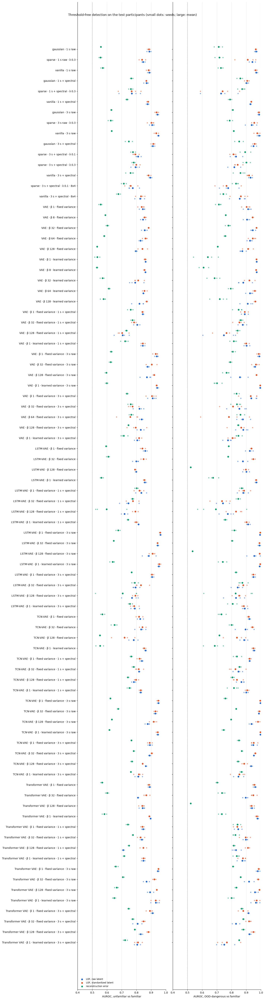

In [5]:
SCORE_C = dict(zip(ns.SCORES, ['#2266cc', '#e0572b', '#0f9d6e']))      # validated categorical palette (latent notebook)
fig, axes = plt.subplots(1, 2, figsize = (13, 0.55 * len(MODEL_ORDER) + 1.8), sharey = True)
y = {m: i for i, m in enumerate(MODEL_ORDER[::-1])}
for ax, metric in zip(axes, ['AUROC, unfamiliar vs familiar', 'AUROC, OOD-dangerous vs familiar']):
    for k, (score, color) in enumerate(SCORE_C.items()):
        part = results[results['score'] == score]
        offset = (k - 1) * 0.22
        ax.scatter(part[metric], part['model'].map(y) + offset, s = 10, color = color, alpha = .45)
        means = part.groupby('model')[metric].mean()
        ax.scatter(means.values, means.index.map(y) + offset, s = 46, color = color, label = score, edgecolor = 'white', linewidth = .8)
    ax.axvline(0.5, color = '#888', lw = .8, ls = '--')
    ax.set(xlabel = metric, xlim = (0.4, 1.0))
    ax.grid(axis = 'x', alpha = .3)
axes[0].set_yticks(list(y.values()), list(y.keys()))
axes[0].legend(loc = 'lower left', fontsize = 8, frameon = False)
fig.suptitle('Threshold-free detection on the test participants (small dots: seeds; large: mean)', fontsize = 11)
plt.tight_layout(); plt.show()

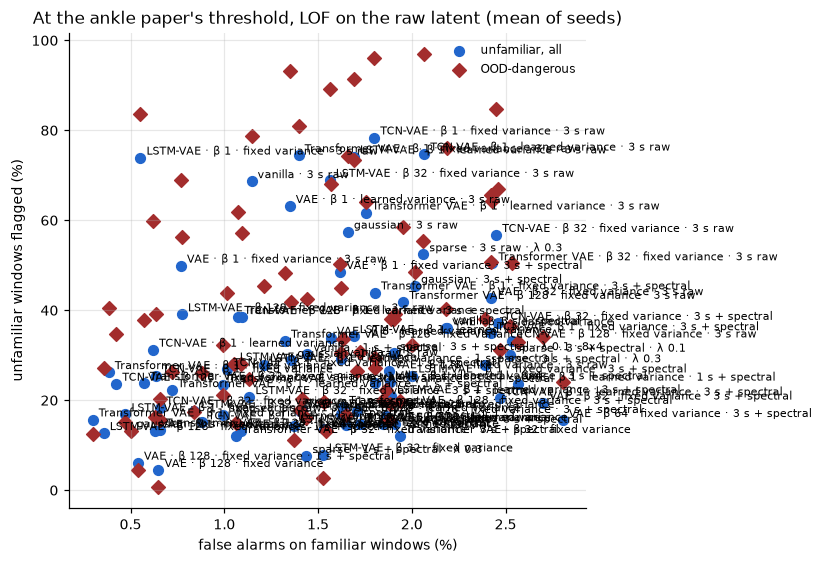

In [6]:
fig, ax = plt.subplots(figsize = (7.5, 5.2))
part = results[results['score'] == 'LOF, raw latent'].groupby('model')[['false alarms, familiar (%)', 'flagged, unfamiliar (%)',
                                                                        'flagged, OOD-dangerous (%)']].mean().reindex(MODEL_ORDER)
ax.scatter(part['false alarms, familiar (%)'], part['flagged, unfamiliar (%)'], s = 40, color = '#2266cc', label = 'unfamiliar, all')
ax.scatter(part['false alarms, familiar (%)'], part['flagged, OOD-dangerous (%)'], s = 40, color = '#a32d2d', marker = 'D', label = 'OOD-dangerous')
for m, row in part.iterrows():
    ax.annotate(m, (row['false alarms, familiar (%)'], row['flagged, unfamiliar (%)']), fontsize = 7, xytext = (4, 2), textcoords = 'offset points')
ax.set(xlabel = 'false alarms on familiar windows (%)', ylabel = 'unfamiliar windows flagged (%)',
       title = 'At the ankle paper\'s threshold, LOF on the raw latent (mean of seeds)')
ax.legend(fontsize = 8, frameon = False); ax.grid(alpha = .3); plt.tight_layout(); plt.show()

## 4. Task by task

Share of each task's test windows flagged as unfamiliar (filtered score above the threshold), mean of seeds. The first
four columns are the familiar tasks, so their values are false alarms; for every other column higher is better.

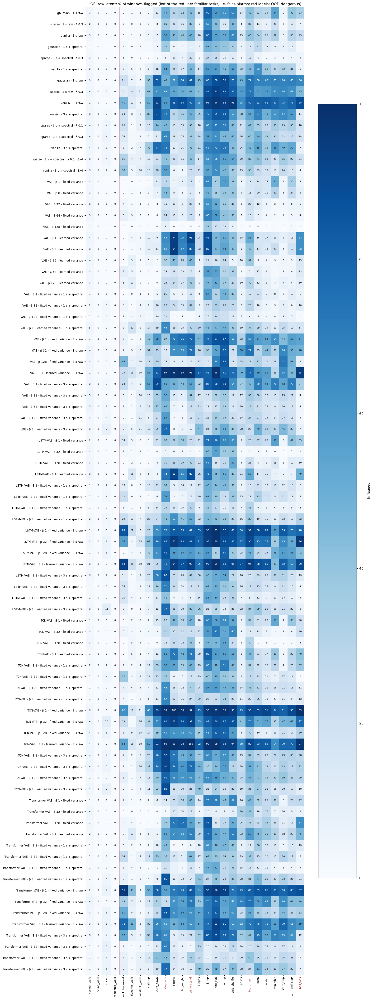

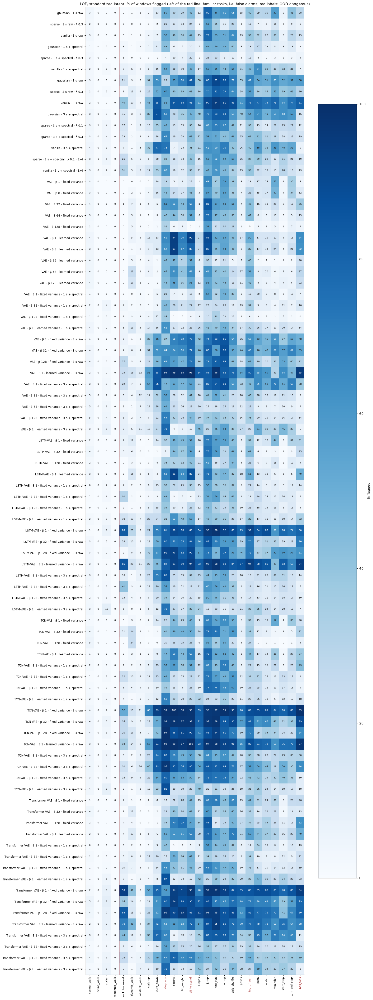

In [7]:
TASKS = list(FAMILIAR) + [t for ts in nt.TASK_FAMILIES.values() for t in ts if t not in FAMILIAR]
for score in ('LOF, raw latent', 'LOF, standardized latent'):
    grid = per_task.xs(score, level = 'score').groupby(level = 'model').mean().reindex(index = MODEL_ORDER, columns = TASKS)
    fig, ax = plt.subplots(figsize = (14, 0.42 * len(MODEL_ORDER) + 2.2))
    im = ax.imshow(grid.to_numpy(), aspect = 'auto', cmap = 'Blues', vmin = 0, vmax = 100)
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            v = grid.iat[i, j]
            ax.text(j, i, f'{v:.0f}', ha = 'center', va = 'center', fontsize = 6.5, color = 'white' if v > 60 else '#222')
    ax.set_xticks(range(len(TASKS)), TASKS, rotation = 90, fontsize = 7.5)
    ax.set_yticks(range(len(MODEL_ORDER)), MODEL_ORDER, fontsize = 8)
    ax.axvline(len(FAMILIAR) - .5, color = '#a32d2d', lw = 1.5)
    for t in nt.OOD_DANGEROUS_TASKS:
        ax.get_xticklabels()[TASKS.index(t)].set_color('#a32d2d')
    ax.set_title(f'{score}: % of windows flagged (left of the red line: familiar tasks, i.e. false alarms; red labels: OOD-dangerous)', fontsize = 9.5)
    fig.colorbar(im, ax = ax, shrink = .8, label = '% flagged'); plt.tight_layout(); plt.show()

## 5. Where the scores fall

For the model with the best mean AUROC under LOF on the raw latent (seed 0): each task's filtered scores relative to
the threshold (1 = threshold, log scale). Boxes span the middle half of windows, whiskers 5 to 95%.

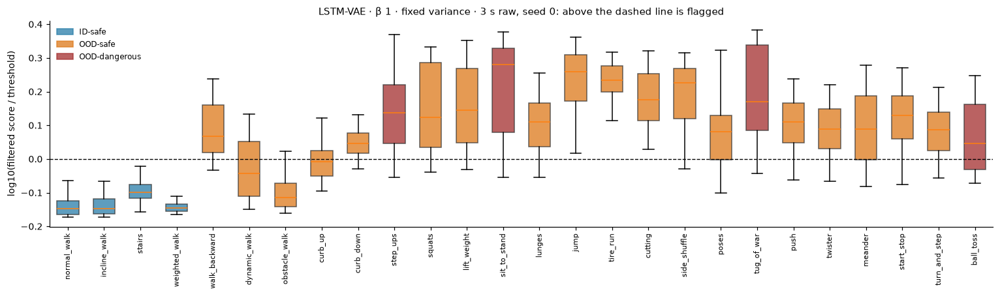

In [8]:
lof_raw = results[results['score'] == 'LOF, raw latent']
best = lof_raw.groupby('model')['AUROC, unfamiliar vs familiar'].mean().idxmax()
r = runs[runs['model'] == best].sort_values('seed').iloc[0]                 # seed 0 when it exists
labels = test_labels[r.run]
keep = pd.MultiIndex.from_frame(labels[['rec', 'end']]).isin(COMMON)
cal, test = ns.get_scores(r.run, exports[r.run], 'LOF, raw latent', CACHE)
lab = labels[keep].reset_index(drop = True)
filtered = ns.get_causal_median(test[keep], lab['rec'].to_numpy(), lab['end'].to_numpy()) / np.percentile(cal, 99.5)
CLASS_C = {'ID-safe': '#287da8', 'OOD-safe': '#dd791a', 'OOD-dangerous': '#a32d2d'}
fig, ax = plt.subplots(figsize = (14, 4.2))
data = [np.log10(np.clip(filtered[lab['task'].astype(str).to_numpy() == t], 1e-3, None)) for t in TASKS]
bp = ax.boxplot(data, whis = (5, 95), showfliers = False, patch_artist = True, widths = .6)
for patch, t in zip(bp['boxes'], TASKS):
    patch.set(facecolor = CLASS_C[nt.get_controller_class(t)], alpha = .75, edgecolor = '#333')
ax.axhline(0, color = 'k', lw = .9, ls = '--')
ax.set_xticks(range(1, len(TASKS) + 1), TASKS, rotation = 90, fontsize = 7.5)
ax.set_ylabel('log10(filtered score / threshold)')
handles = [plt.Rectangle((0, 0), 1, 1, color = c, alpha = .75, label = k) for k, c in CLASS_C.items()]
ax.legend(handles = handles, fontsize = 8, frameon = False, loc = 'upper left')
ax.set_title(f'{best}, seed {r.seed}: above the dashed line is flagged', fontsize = 10)
plt.tight_layout(); plt.show()

## 6. The operating point on held-out people, and LOF in fewer dimensions

Sections 3 to 5 follow the ankle paper's rule: the threshold is the 99.5th percentile of the calibration scores of
*training* people, and LOF runs on all 32 latent units as exported. Section 7 of notebook 01 and section 5 here both
found that rule too cautious, and the Science Robotics VAE study found LOF better in fewer dimensions
(`ml/sci_rob/VAE/results/posthoc_dims.md`). Both choices are made here on the four **validation participants**
(BT09, BT12, BT13, BT21), whose latents come from each run's saved checkpoint through
`ml/nature/awareness/encode_split.py`, so the test participants stay untouched until the last step.

| step | rule |
|---|---|
| representation | the latent as exported (`raw`, as in sections 3 to 5); every unit standardized by the fit set (`all units`); or that standardized latent projected onto k principal components fitted on the fit set, k in {4, 6, 8, 12, 16, 24} |
| threshold | the filtered score that flags 1% of the familiar validation windows (the false-alarm target), per run |
| choice of k | per model, the representation with the highest mean recall of unfamiliar validation windows at that threshold; ties go to fewer dimensions |
| test | the chosen representation with each seed's own threshold, scored once on the test windows of section 1 |

LOF is still fitted on the fit part of each run's exported training windows (k = 20), and the 0.5 s causal median is
still applied before the threshold. Validation windows are those every run exported, as for test. Runs without
validation latents are listed and left out.

In [9]:
REPRESENTATIONS = ['raw', None, *ns.PCA_KS]
rep_label = lambda r: 'raw' if r == 'raw' else 'all units' if r is None else f'PCA-{r}'      # noqa: E731
DIMS = {'raw': 32, 'all units': 32, **{f'PCA-{k}': k for k in ns.PCA_KS}}
REP_BY_DIMS = sorted(DIMS, key = lambda r: (DIMS[r], r == 'raw'))                           # PCA-4 ... PCA-24, all units, raw

val_exports = {r.run: ns.load_split_export(r.run, tables[r.inputs]) for r in runs.itertuples()}
with_val = runs[runs['run'].map(lambda r: val_exports[r] is not None)]
missing = sorted(set(runs['model']) - set(with_val['model']))
print(f'{len(with_val)} runs of {with_val["model"].nunique()} models have validation latents' + (f'; without: {missing}' if missing else ''))
val_labels = {run: val_exports[run]['labels'] for run in with_val['run']}
COMMON_VAL = reduce(lambda a, b: a.intersection(b), [pd.MultiIndex.from_frame(l[['rec', 'end']]) for l in val_labels.values()])
first_val = next(iter(val_labels.values()))
shown_val = first_val[pd.MultiIndex.from_frame(first_val[['rec', 'end']]).isin(COMMON_VAL)]
print(f'{len(COMMON_VAL):,} validation windows common to every run (participants {sorted(shown_val.subject.astype(str).unique())})')
display(shown_val.groupby('controller_class', observed = True).size().rename('windows').to_frame().T)

t0 = time.time()
rows, per_task_tuned = [], []
for r in with_val.itertuples():
    labels_v, labels_t = val_labels[r.run], test_labels[r.run]
    keep_v = pd.MultiIndex.from_frame(labels_v[['rec', 'end']]).isin(COMMON_VAL)
    keep_t = pd.MultiIndex.from_frame(labels_t[['rec', 'end']]).isin(COMMON)
    lab_v, lab_t = labels_v[keep_v].reset_index(drop = True), labels_t[keep_t].reset_index(drop = True)
    for rep in REPRESENTATIONS:
        cal, val, test = ns.get_split_scores(r.run, exports[r.run], val_exports[r.run], rep, CACHE)
        threshold = ns.tune_threshold(ns.get_filtered(val[keep_v], lab_v), lab_v, FAMILIAR)
        ankle = float(np.percentile(cal, ns.THRESHOLD_PERCENTILE))
        m_val, _ = ns.evaluate_at(threshold, val[keep_v], lab_v, FAMILIAR)
        m_test, flagged = ns.evaluate_at(threshold, test[keep_t], lab_t, FAMILIAR)
        m_ankle, _ = ns.evaluate_at(ankle, test[keep_t], lab_t, FAMILIAR)
        rows.append({'model': r.model, 'seed': r.seed, 'representation': rep_label(rep), 'threshold': threshold, 'ankle threshold': ankle,
                     **{f'val {k}': v for k, v in m_val.items()}, **{f'test {k}': v for k, v in m_test.items()},
                     **{f'ankle test {k}': v for k, v in m_ankle.items()}})
        per_task_tuned.append(flagged.rename((r.model, r.seed, rep_label(rep))))
step1 = pd.DataFrame(rows)
per_task_tuned = pd.DataFrame(per_task_tuned)
per_task_tuned.index = pd.MultiIndex.from_tuples(per_task_tuned.index, names = ['model', 'seed', 'representation'])
print(f'scored {len(with_val)} runs x {len(REPRESENTATIONS)} representations in {time.time() - t0:.0f} s')

258 runs of 86 models have validation latents


173,590 validation windows common to every run (participants ['BT09', 'BT12', 'BT13', 'BT21'])


controller_class,ID-safe,OOD-dangerous,OOD-safe
windows,35345,22159,116086


scored 258 runs x 8 representations in 1534 s


### 6.1 Choosing the representation on validation

Mean recall of unfamiliar validation windows at the 1% false-alarm threshold, by representation (columns in order of
dimension). The chosen column is the maximum; the test participants have not been looked at yet.

In [10]:
MODELS_VAL = [m for m in MODEL_ORDER if m in set(with_val['model'])]
val_recall = (step1.groupby(['model', 'representation'])['val flagged, unfamiliar (%)'].mean()
              .unstack().reindex(index = MODELS_VAL, columns = REP_BY_DIMS))
chosen = val_recall.idxmax(axis = 1)                                      # the first maximum: fewest dimensions on a tie
val_auroc = (step1.groupby(['model', 'representation'])['val AUROC, unfamiliar vs familiar'].mean()
             .unstack().reindex(index = MODELS_VAL, columns = REP_BY_DIMS))
print('recall of unfamiliar validation windows at 1% false alarms (%), mean of seeds')
display(val_recall.round(1).assign(chosen = chosen))
print('AUROC on validation, unfamiliar vs familiar (threshold-free), mean of seeds')
display(val_auroc.round(3))

recall of unfamiliar validation windows at 1% false alarms (%), mean of seeds


representation,PCA-4,PCA-6,PCA-8,PCA-12,PCA-16,PCA-24,all units,raw,chosen
model,,,,,,,,,
gaussian · 1 s raw,16.9,25.3,29.0,31.7,32.9,33.2,32.7,33.0,PCA-24
sparse · 1 s raw · λ 0.3,4.6,4.5,7.0,14.2,20.5,22.9,23.8,26.2,raw
vanilla · 1 s raw,6.6,16.0,22.2,29.4,33.2,31.6,30.4,31.6,PCA-16
gaussian · 1 s + spectral,20.8,22.2,26.9,28.9,29.4,30.1,29.3,33.1,raw
sparse · 1 s + spectral · λ 0.3,5.5,6.4,6.9,8.4,9.8,9.6,9.2,9.4,PCA-16
...,...,...,...,...,...,...,...,...,...
Transformer VAE · β 1 · learned variance · 3 s raw,15.2,24.1,30.8,20.1,26.7,45.7,54.2,53.5,all units
Transformer VAE · β 1 · fixed variance · 3 s + spectral,26.0,35.9,38.6,40.9,37.6,39.1,41.7,44.7,raw
Transformer VAE · β 32 · fixed variance · 3 s + spectral,14.5,17.8,19.3,16.7,19.2,21.9,25.3,11.8,all units


AUROC on validation, unfamiliar vs familiar (threshold-free), mean of seeds


representation,PCA-4,PCA-6,PCA-8,PCA-12,PCA-16,PCA-24,all units,raw
model,,,,,,,,
gaussian · 1 s raw,0.746,0.774,0.811,0.845,0.863,0.864,0.859,0.865
sparse · 1 s raw · λ 0.3,0.516,0.514,0.548,0.689,0.764,0.805,0.818,0.830
vanilla · 1 s raw,0.686,0.757,0.798,0.844,0.860,0.867,0.862,0.867
gaussian · 1 s + spectral,0.718,0.746,0.790,0.828,0.836,0.837,0.834,0.837
sparse · 1 s + spectral · λ 0.3,0.583,0.585,0.586,0.676,0.722,0.749,0.749,0.750
...,...,...,...,...,...,...,...,...
Transformer VAE · β 1 · learned variance · 3 s raw,0.657,0.716,0.750,0.720,0.808,0.867,0.908,0.912
Transformer VAE · β 1 · fixed variance · 3 s + spectral,0.729,0.757,0.788,0.824,0.818,0.852,0.857,0.880
Transformer VAE · β 32 · fixed variance · 3 s + spectral,0.670,0.723,0.749,0.728,0.745,0.785,0.804,0.758


### 6.2 Test: the ankle rule against the tuned threshold

Three settings per model, mean ± SD over seeds, scored on the test participants: the ankle paper's rule on the raw
latent (sections 3 to 5); the tuned threshold on the raw latent (what the threshold alone buys); and the tuned
threshold in the representation chosen in 6.1 (what fewer dimensions add). False alarms are the share of familiar
test windows flagged; recall the share of unfamiliar or OOD-dangerous ones.

The figure after the table shows the dense latents only (plain and Gaussian-NLL, 4 x 8), one colour per
model throughout section 6; the sparse and 8 x 4 models are in the tables.

In [11]:
def get_setting_rows(frame, prefix, setting):
    """One tidy row per run for a (threshold rule, representation) setting."""
    out = pd.DataFrame({'model': frame['model'], 'seed': frame['seed'], 'setting': setting,
                        'false alarms (%)': frame[f'{prefix} false alarms, familiar (%)'],
                        'recall, unfamiliar (%)': frame[f'{prefix} flagged, unfamiliar (%)'],
                        'recall, OOD-dangerous (%)': frame[f'{prefix} flagged, OOD-dangerous (%)'],
                        'AUROC, unfamiliar': frame[f'{prefix} AUROC, unfamiliar vs familiar'],
                        'AUROC, OOD-dangerous': frame[f'{prefix} AUROC, OOD-dangerous vs familiar']})
    return out

raw = step1[step1['representation'] == 'raw']
at_chosen = step1[step1['representation'] == step1['model'].map(chosen)]
SETTINGS = ['ankle rule, raw latent', 'tuned threshold, raw latent', 'tuned threshold, chosen representation']
summary = pd.concat([get_setting_rows(raw, 'ankle test', SETTINGS[0]), get_setting_rows(raw, 'test', SETTINGS[1]),
                     get_setting_rows(at_chosen, 'test', SETTINGS[2])], ignore_index = True)
summary['validation false alarms (%)'] = pd.concat([raw['ankle test false alarms, familiar (%)'] * np.nan,
                                                   raw['val false alarms, familiar (%)'], at_chosen['val false alarms, familiar (%)']]).to_numpy()
COLS = ['false alarms (%)', 'recall, unfamiliar (%)', 'recall, OOD-dangerous (%)', 'AUROC, unfamiliar', 'AUROC, OOD-dangerous']
agg = summary.groupby(['model', 'setting'], sort = False)[COLS].agg(['mean', 'std'])
fmt = lambda c: '{:.3f}' if c.startswith('AUROC') else '{:.1f}'          # noqa: E731
table = pd.DataFrame({c: agg[(c, 'mean')].map(fmt(c).format) + ' ± ' + agg[(c, 'std')].map(fmt(c).format) for c in COLS})
table.insert(0, 'representation', [chosen[m] if s == SETTINGS[2] else 'raw' for m, s in table.index])
table = table.reindex(pd.MultiIndex.from_product([MODELS_VAL, SETTINGS], names = ['model', 'setting']))
display(table)

representation false alarms (%) recall, unfamiliar (%) recall, OOD-dangerous (%) AUROC, unfamiliar  \
model                                                     setting                                                                                                                                     
gaussian · 1 s raw                                        ankle rule, raw latent                            raw        1.4 ± 0.0             29.0 ± 4.0                42.0 ± 5.9     0.887 ± 0.014   
                                                          tuned threshold, raw latent                       raw        2.0 ± 0.5             34.3 ± 0.9                48.1 ± 1.3     0.887 ± 0.014   
                                                          tuned threshold, chosen representation         PCA-24        1.9 ± 0.5             35.0 ± 0.8                49.8 ± 1.6     0.888 ± 0.006   
sparse · 1 s raw · λ 0.3                                  ankle rule, raw latent                            raw        1.0 ± 0.2             16.8 ± 0.4                32.2 ± 7.4     0.846 ± 0.011   
                                                          tuned threshold, raw latent                       raw        1.7 ± 0.1             26.9 ± 2.1                45.7 ± 5.9     0.846 ± 0.011   
...                                                                                                         ...              ...                    ...                       ...               ...   
Transformer VAE · β 128 · fixed variance · 3 s + spectral tuned threshold, raw latent                       raw        1.0 ± 0.4             13.4 ± 5.7               25.2 ± 14.4     0.829 ± 0.012   
                                                          tuned threshold, chosen representation      all units        2.6 ± 0.5             42.0 ± 6.2               62.9 ± 11.3     0.881 ± 0.009   
Transformer VAE · β 1 · learned variance · 3 s + spectral ankle rule, raw latent                            raw        1.0 ± 0.5             23.4 ± 4.1                21.1 ± 7.5     0.805 ± 0.020   
                                                          tuned threshold, raw latent                       raw        1.2 ± 0.3             24.8 ± 2.2                22.3 ± 7.4     0.805 ± 0.020   
                                                          tuned threshold, chosen representation          PCA-6        1.9 ± 1.2             35.4 ± 2.1                38.2 ± 4.4     0.813 ± 0.019   

                                                                                                 AUROC, OOD-dangerous  
model                                                     setting                                                      
gaussian · 1 s raw                                        ankle rule, raw latent                        0.966 ± 0.009  
                                                          tuned threshold, raw latent                   0.966 ± 0.009  
                                                          tuned threshold, chosen representation        0.967 ± 0.003  
sparse · 1 s raw · λ 0.3                                  ankle rule, raw latent                        0.941 ± 0.021  
                                                          tuned threshold, raw latent                   0.941 ± 0.021  
...                                                                                                               ...  
Transformer VAE · β 128 · fixed variance · 3 s + spectral tuned threshold, raw latent                   0.922 ± 0.008  
                                                          tuned threshold, chosen representation        0.948 ± 0.012  
Transformer VAE · β 1 · learned variance · 3 s + spectral ankle rule, raw latent                        0.750 ± 0.064  
                                                          tuned threshold, raw latent                   0.750 ± 0.064  
                                                          tuned thres

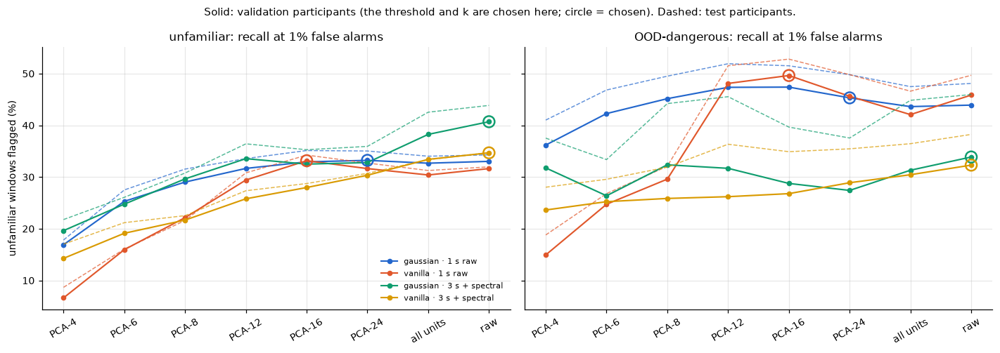

In [12]:
FIG_DIR = Path.cwd() / 'figures'
FIG_DIR.mkdir(exist_ok = True)
# colour follows the model, never its position; dense (non-sparse, 4 x 8) latents only, every model is in the tables
MODEL_C = {'gaussian · 1 s raw': '#2266cc', 'vanilla · 1 s raw': '#e0572b',              # validated in this order
           'gaussian · 3 s + spectral': '#0f9d6e', 'vanilla · 3 s + spectral': '#d99a00'}
DENSE = [m for m in MODEL_C if m in MODELS_VAL]
x = np.arange(len(REP_BY_DIMS))
fig, axes = plt.subplots(1, 2, figsize = (13, 4.6), sharey = True)
for ax, what in zip(axes, ['unfamiliar', 'OOD-dangerous']):
    for m in DENSE:
        part = step1[step1['model'] == m].groupby('representation')
        v = part[f'val flagged, {what} (%)'].mean().reindex(REP_BY_DIMS)
        t = part[f'test flagged, {what} (%)'].mean().reindex(REP_BY_DIMS)
        ax.plot(x, v, '-o', color = MODEL_C[m], ms = 4, lw = 1.4, label = m)
        ax.plot(x, t, '--', color = MODEL_C[m], lw = 1.0, alpha = .7)
        j = REP_BY_DIMS.index(chosen[m])
        ax.scatter([j], [v.iloc[j]], s = 110, facecolor = 'none', edgecolor = MODEL_C[m], lw = 1.6, zorder = 5)
    ax.set_xticks(x, REP_BY_DIMS, rotation = 30)
    ax.set(ylabel = f'{what} windows flagged (%)' if what == 'unfamiliar' else '', title = f'{what}: recall at 1% false alarms')
    ax.grid(alpha = .3)
axes[0].legend(fontsize = 7.5, frameon = False, loc = 'lower right')
fig.suptitle('Solid: validation participants (the threshold and k are chosen here; circle = chosen). Dashed: test participants.', fontsize = 9.5)
plt.tight_layout(); fig.savefig(FIG_DIR / '05_step1_recall_by_representation.png', dpi = 160); plt.show()

### 6.3 Task by task at the tuned threshold

Share of each task's test windows flagged with the chosen representation and the 1% false-alarm threshold, mean of
seeds. Compare with section 4 (the ankle rule): the first four columns should sit near 1 instead of near 0, and every
other column should rise.

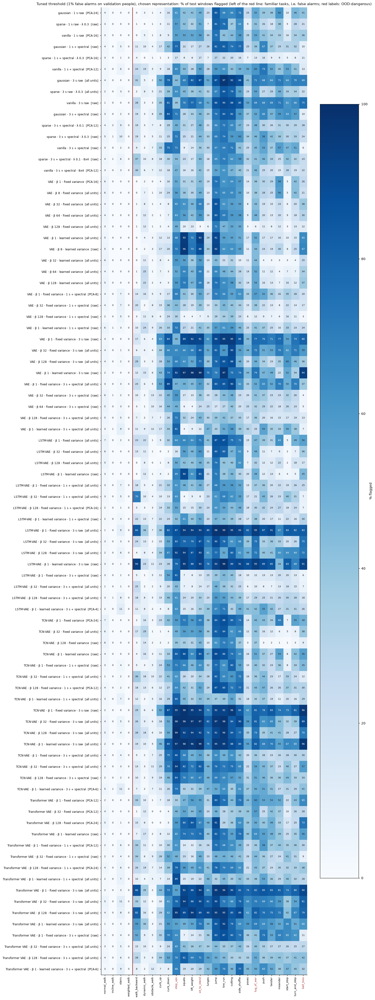

In [13]:
grid = pd.concat([per_task_tuned.xs((m, chosen[m]), level = ('model', 'representation')).mean().rename(m) for m in MODELS_VAL], axis = 1).T
grid = grid.reindex(columns = TASKS)
fig, ax = plt.subplots(figsize = (14, 0.42 * len(MODELS_VAL) + 2.2))
im = ax.imshow(grid.to_numpy(), aspect = 'auto', cmap = 'Blues', vmin = 0, vmax = 100)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.iat[i, j]
        ax.text(j, i, f'{v:.0f}', ha = 'center', va = 'center', fontsize = 6.5, color = 'white' if v > 60 else '#222')
ax.set_xticks(range(len(TASKS)), TASKS, rotation = 90, fontsize = 7.5)
ax.set_yticks(range(len(MODELS_VAL)), [f'{m}  [{chosen[m]}]' for m in MODELS_VAL], fontsize = 8)
ax.axvline(len(FAMILIAR) - .5, color = '#a32d2d', lw = 1.5)
for t in nt.OOD_DANGEROUS_TASKS:
    ax.get_xticklabels()[TASKS.index(t)].set_color('#a32d2d')
ax.set_title('Tuned threshold (1% false alarms on validation people), chosen representation: % of test windows flagged '
             '(left of the red line: familiar tasks, i.e. false alarms; red labels: OOD-dangerous)', fontsize = 9.5)
fig.colorbar(im, ax = ax, shrink = .8, label = '% flagged'); plt.tight_layout()
fig.savefig(FIG_DIR / '05_step1_per_task.png', dpi = 160); plt.show()

### 6.4 The trade-off behind the 1% target

For the dense latents (plain and Gaussian-NLL) in their chosen representation: thresholds set on validation for several false-alarm targets,
then the false alarms and recall they give on the test participants (mean of seeds). The ankle rule is the marker.
Where the curve bends is where a different target would be worth it.

false alarms (%)                                                                      recall, unfamiliar (%)                                                                       \
model      gaussian · 1 s raw gaussian · 3 s + spectral vanilla · 1 s raw vanilla · 3 s + spectral     gaussian · 1 s raw gaussian · 3 s + spectral vanilla · 1 s raw vanilla · 3 s + spectral   
target (%)                                                                                                                                                                                       
0.2                       1.1                       1.0               0.8                      1.2                   26.2                      28.8              21.0                     21.6   
0.5                       1.4                       1.4               1.2                      1.6                   30.1                      35.6              26.5                     28.4   
1.0                       1.9                       1.9               1.7                      2.0                   35.0                      43.9              34.2                     34.7   
2.0                       2.7                       2.7               2.3                      2.7                   43.4                      53.7              44.0                     42.4   
3.0                       3.6                       3.7               2.8                      3.2                   51.9                      61.7              51.5                     47.4   
5.0                       4.8                       4.9               3.7                      4.2                   63.4                      69.7              61.0                     55.2   

           recall, OOD-dangerous (%)                                                                       
model             gaussian · 1 s raw gaussian · 3 s + spectral vanilla · 1 s raw vanilla · 3 s + spectral  
target (%)                                                                                                 
0.2                             40.3                      24.4              39.0                     21.1  
0.5                             44.5                      33.2              44.4                     30.4  
1.0                             49.8                      46.0              52.8                     38.2  
2.0                             57.5                      61.0              63.2                     48.5  
3.0                             66.6                      71.9              71.4                     54.7  
5.0                             80.3                      80.3              81.4                     63.7

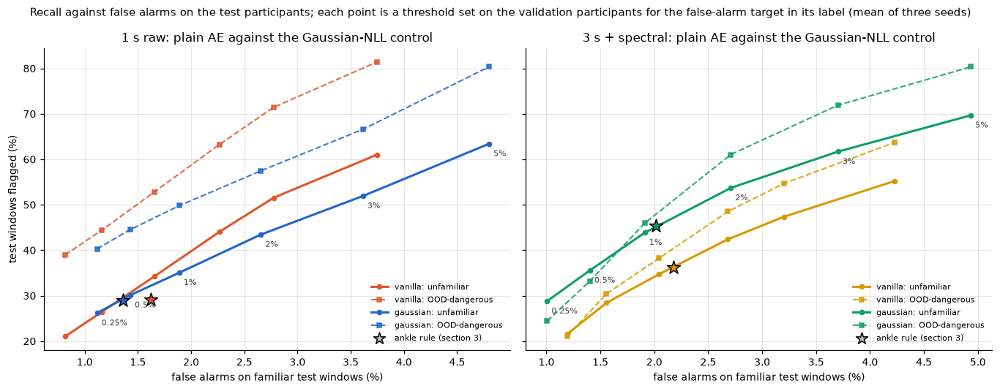

In [14]:
TARGETS = (0.25, 0.5, 1.0, 2.0, 3.0, 5.0)
curves = []
for r in with_val[with_val['model'].isin(DENSE)].itertuples():
    rep = next(k for k in REPRESENTATIONS if rep_label(k) == chosen[r.model])
    labels_v, labels_t = val_labels[r.run], test_labels[r.run]
    keep_v = pd.MultiIndex.from_frame(labels_v[['rec', 'end']]).isin(COMMON_VAL)
    keep_t = pd.MultiIndex.from_frame(labels_t[['rec', 'end']]).isin(COMMON)
    lab_v, lab_t = labels_v[keep_v].reset_index(drop = True), labels_t[keep_t].reset_index(drop = True)
    _, val, test = ns.get_split_scores(r.run, exports[r.run], val_exports[r.run], rep, CACHE)
    filt_v, filt_t = ns.get_filtered(val[keep_v], lab_v), ns.get_filtered(test[keep_t], lab_t)
    tasks_t, cls_t = lab_t['task'].astype(str).to_numpy(), lab_t['controller_class'].astype(str).to_numpy()
    fam_t = np.isin(tasks_t, FAMILIAR)
    for target in TARGETS:
        thr = ns.tune_threshold(filt_v, lab_v, FAMILIAR, target)
        curves.append({'model': r.model, 'seed': r.seed, 'target (%)': target, 'false alarms (%)': 100 * (filt_t[fam_t] > thr).mean(),
                       'recall, unfamiliar (%)': 100 * (filt_t[~fam_t] > thr).mean(),
                       'recall, OOD-dangerous (%)': 100 * (filt_t[cls_t == 'OOD-dangerous'] > thr).mean()})
curves = pd.DataFrame(curves)
mean_curves = curves.groupby(['model', 'target (%)']).mean(numeric_only = True).reset_index()
display(mean_curves.round(1).pivot(index = 'target (%)', columns = 'model', values = ['false alarms (%)', 'recall, unfamiliar (%)', 'recall, OOD-dangerous (%)']))

PAIRS = {'1 s raw': ['vanilla · 1 s raw', 'gaussian · 1 s raw'],
         '3 s + spectral': ['vanilla · 3 s + spectral', 'gaussian · 3 s + spectral']}
fig, axes = plt.subplots(1, 2, figsize = (12.5, 4.9), sharey = True)
for ax, (inputs, models) in zip(axes, PAIRS.items()):
    for m in [m for m in models if m in DENSE]:
        part = mean_curves[mean_curves['model'] == m]
        ax.plot(part['false alarms (%)'], part['recall, unfamiliar (%)'], '-o', color = MODEL_C[m], ms = 4, lw = 2, label = f'{m.split(" · ")[0]}: unfamiliar')
        ax.plot(part['false alarms (%)'], part['recall, OOD-dangerous (%)'], '--s', color = MODEL_C[m], ms = 4, lw = 1.4, alpha = .85,
                label = f'{m.split(" · ")[0]}: OOD-dangerous')
        ankle_m = summary[(summary['model'] == m) & (summary['setting'] == SETTINGS[0])].mean(numeric_only = True)
        ax.scatter([ankle_m['false alarms (%)']], [ankle_m['recall, unfamiliar (%)']], marker = '*', s = 150, color = MODEL_C[m],
                   edgecolor = 'k', zorder = 5)
        if m.startswith('gaussian'):                                            # target labels on one line per panel
            for _, row in part.iterrows():
                ax.annotate(f"{row['target (%)']:g}%", (row['false alarms (%)'], row['recall, unfamiliar (%)']), fontsize = 7.5,
                            xytext = (4, -11), textcoords = 'offset points', color = '#444')
    ax.scatter([], [], marker = '*', s = 120, color = '#bbb', edgecolor = 'k', label = 'ankle rule (section 3)')
    ax.set(xlabel = 'false alarms on familiar test windows (%)', title = f'{inputs}: plain AE against the Gaussian-NLL control')
    ax.grid(alpha = .3); ax.legend(fontsize = 7.5, frameon = False, loc = 'lower right')
axes[0].set_ylabel('test windows flagged (%)')
fig.suptitle('Recall against false alarms on the test participants; each point is a threshold set on the validation participants '
             'for the false-alarm target in its label (mean of three seeds)', fontsize = 9.5)
plt.tight_layout(); fig.savefig(FIG_DIR / '05_step1_operating_curve.png', dpi = 160); plt.show()


### 6.5 What changed

- **A threshold set on held-out people does not transfer exactly to other people.** The 1% false-alarm target on the
  validation participants gives 1.7 to 2.0% false alarms on the test participants for the vanilla latents (0.8 to 1.2%
  for a 0.25% target), and the ankle rule's 99.5th percentile of training people gave 1.6 to 2.2% in section 3. The
  familiar score level differs between people by about a factor of two in false alarms, so the false-alarm rate an
  exoskeleton sees is set by its wearer, not by the training set. A short calibration bout of familiar walking per
  wearer is the natural fix.
- **Tuning the threshold alone buys little recall at matched false alarms.** On the vanilla 1 s latent, 29 to 32% of
  unfamiliar windows (1.6 to 1.8% false alarms); on the vanilla 3 s + spectral latent nothing (36 to 35% at 2.2 to
  2.0%). The ankle rule already sat on the same trade-off curve.
- **Fewer dimensions help the vanilla 1 s latent, and only that one.** Validation picks PCA-16 for it, and on test it
  flags 34.2 ± 6.0% of unfamiliar and 52.8 ± 10.0% of OOD-dangerous windows at 1.7% false alarms, against 29.2 ± 4.0%
  and 44.9 ± 7.1% at 1.6% under the ankle rule; AUROC is unchanged (0.883 against 0.887; 0.968 both). For the 3 s +
  spectral and the sparse latents validation keeps the raw latent, and the projections cost recall below 12 to 16
  components everywhere. With three seeds the ±6 to ±10 point spread puts PCA-16 against raw on the same model within
  noise: the direction agrees with the Science Robotics result, the size is not established.
- **The false-alarm target is the real lever.** On the vanilla 1 s latent (PCA-16), raising the target from 1 to 2%
  takes recall from 34 to 44% of unfamiliar and from 53 to 63% of OOD-dangerous windows at 2.3% false alarms; a 5%
  target flags 61% and 81% at 3.7%. The curve has no knee: recall at any low false-alarm rate is bounded by the
  ranking (AUROC 0.88), because unfamiliar scores straddle the familiar range (section 5). Which target to run is a
  controller decision, the share of walking windows that may be handed to the fallback controller, not a detector one.
- **Task by task** (vanilla 1 s, PCA-16, 1% target): jumping 75%, side shuffle 58%, sit-to-stand 56%, step-ups 55%,
  squats and lifting 52 to 53%, tug of war 53%; the ball toss rises to 36% (23% under the ankle rule) and standing
  poses to 29%. Near-familiar walking stays unflagged (walking backward 0%, obstacle walk 1%, dynamic walk 5%, curb up
  8%), and the few false alarms fall on normal walking (3%), none on incline, weighted or stair walking.

### 6.6 The Gaussian-NLL control (`gaussian`)

The Science Robotics VAE study's best model was a deterministic control: the AE's encoder ending at its last convolution
(no BatchNorm, no ReLU, so the latent is linear) trained on the unit-variance Gaussian NLL summed per window
(`ml/nature/awareness/train_ae.py --variant gaussian`; three seeds per input setting, same data and settings as the
plain AE). Under Adam the NLL is the MSE times a constant, so the latent head is the only substantive change.

- **1 s input: no gain.** AUROC is unchanged (0.887 ± 0.014 against 0.887 ± 0.010 for unfamiliar tasks, 0.966 against
  0.968 for OOD-dangerous ones). At the 1% target it flags 35.0 ± 0.8% of unfamiliar and 49.8 ± 1.6% of OOD-dangerous
  test windows at 1.9% false alarms, the plain AE 34.2 ± 6.0% and 52.8 ± 10.0% at 1.7%. At higher targets the plain AE's
  curve lies above it (6.4). The control is far more consistent across seeds (SD under 2 points against 6 to 10).
- **3 s + spectral input: better everywhere.** AUROC 0.911 ± 0.012 against 0.893 ± 0.010 for unfamiliar tasks and
  0.949 ± 0.018 against 0.928 ± 0.013 for OOD-dangerous ones; at the 1% target 43.9 ± 3.1% of unfamiliar and 46.0 ± 3.6%
  of OOD-dangerous windows at 1.9% false alarms, against 34.7 ± 3.8% and 38.2 ± 2.5% at 2.0%. The gain holds on the
  validation participants, where the representation was chosen (AUROC 0.890 against 0.864), and along the whole
  operating curve.
- **So the best detector now depends on the job.** The 3 s Gaussian-NLL latent ranks all unfamiliar movement best of
  any model here; the 1 s latents (either head) still rank the OOD-dangerous tasks best (0.966 to 0.968).
- **Against the Science Robotics result** (+0.04 test AUROC there), the linear head gains nothing on 1 s windows here and
  about 0.02 on 3 s windows. Its latent has the same form as a VAE's posterior mean, so it is the right baseline for the
  VAE grid (notebook 02): a VAE must beat this control, not the ReLU AE.

## 7. Every native metric

LOF reads only where a window lands in the latent. Each model family also offers scores of its own, and for a
downstream classifier any of them may carry information LOF does not, including scores that rank unfamiliar movement
*lower* (an inverted score is as informative as a normal one once its direction is known).

| score | families | what it measures | fitted on |
|---|---|---|---|
| LOF, raw latent | all | neighbourhood density in the latent as exported (the ankle paper's score) | fit windows |
| LOF, standardized latent | all | the same, each unit scaled by its spread | fit windows |
| Mahalanobis, latent | all | distance from the familiar windows' mean, in units of their covariance; one matrix-vector product per window | fit windows |
| out-of-range units | all | how far units fire beyond their range on familiar windows, summed: the label-free form of the sparse model's alarm units | fit windows |
| reconstruction error | all | per-window MSE of the reconstruction (of the posterior mean, for the VAE) | none |
| LOF, active dimensions | VAE | LOF on the posterior means, only the dimensions the VAE uses | fit windows |
| KL | VAE | how far the posterior moves from the prior: how much the encoder says about the window | none |
| NLL (decoder) | VAE | how unlikely the window is under the decoder (with its learned variance where it has one) | none |
| negative ELBO | VAE | NLL + KL, the VAE's bound on the window's negative log likelihood | none |
| posterior variance | VAE | the encoder's own uncertainty about z, mean over the active dimensions | fit windows (which dimensions) |

**Protocol.** As in section 6: fitted where needed on the fit part of each run's exported training windows; each score's
direction is set on the validation participants (negated if it ranks unfamiliar windows lower there); the threshold flags
1% of the familiar validation windows after the 0.5 s causal median; the test participants are scored once. AUROC is
reported in the chosen direction, so 0.5 is chance for every score; the direction column says which way it points. For
the fixed-variance VAE the decoder NLL is the reconstruction error times a constant, so the two rank windows identically.

In [15]:
NATIVE_COLS = ['val AUROC, unfamiliar vs familiar', 'test AUROC, unfamiliar vs familiar',
               'test AUROC, OOD-safe vs familiar', 'test AUROC, OOD-dangerous vs familiar',
               'test false alarms, familiar (%)', 'test flagged, unfamiliar (%)', 'test flagged, OOD-dangerous (%)']
t0 = time.time()
rows, native_scores = [], {}
for r in with_val.itertuples():
    family = ns.get_family(r.config)
    labels_v, labels_t = val_labels[r.run], test_labels[r.run]
    keep_v = pd.MultiIndex.from_frame(labels_v[['rec', 'end']]).isin(COMMON_VAL)
    keep_t = pd.MultiIndex.from_frame(labels_t[['rec', 'end']]).isin(COMMON)
    lab_v, lab_t = labels_v[keep_v].reset_index(drop = True), labels_t[keep_t].reset_index(drop = True)
    for name in ns.get_native_names(family):
        v, t = ns.get_native_scores(r.run, exports[r.run], val_exports[r.run], name, CACHE)
        native_scores[(r.run, name)] = (v[keep_v], t[keep_t])
        metrics, _ = ns.evaluate_oriented(v[keep_v], t[keep_t], lab_v, lab_t, FAMILIAR)
        rows.append({'model': r.model, 'family': family, 'seed': r.seed, 'score': name, **metrics})
native = pd.DataFrame(rows)
print(f'{len(native)} (run, score) pairs: {native.model.nunique()} models, {native.score.nunique()} scores, {time.time() - t0:.0f} s')

2355 (run, score) pairs: 86 models, 10 scores, 1498 s


### 7.1 Every model against every score

Test AUROC in the direction chosen on validation, mean over three seeds; ↓ marks a score that flags unfamiliar movement
by being *lower*. Rows follow the model order of the earlier sections (autoencoders, then the VAE grid by decoder variance
and β).

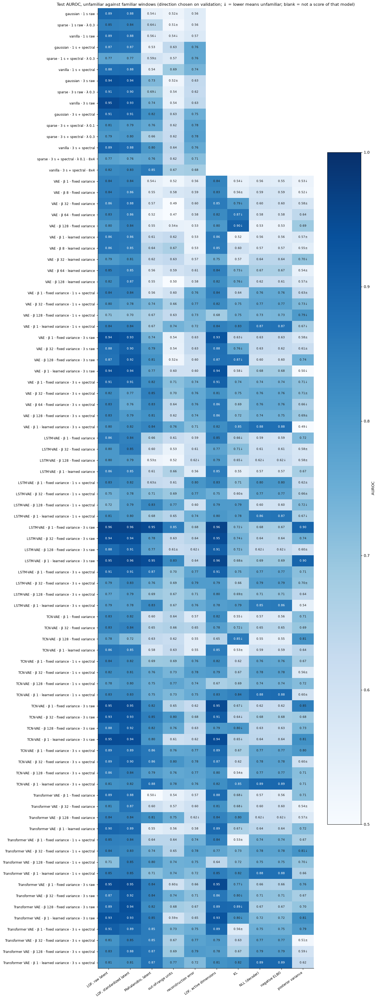

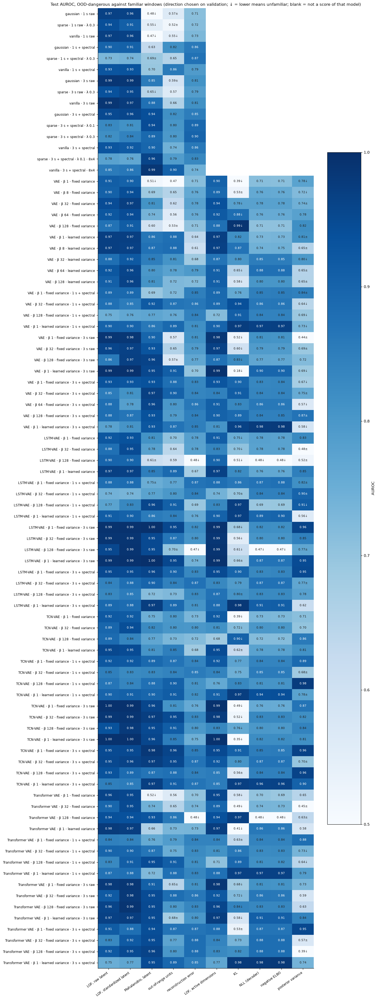

In [16]:
NATIVE_ORDER = list(ns.NATIVE)
MODELS_N = [m for m in MODEL_ORDER if m in set(native['model'])]
mean_n = native.groupby(['model', 'score'])[NATIVE_COLS].mean()
direction = native.groupby(['model', 'score'])['direction'].agg(lambda d: '↓' if (d == 'lower = unfamiliar').all() else ('' if (d == 'higher = unfamiliar').all() else '±'))
for col, what in (('test AUROC, unfamiliar vs familiar', 'unfamiliar'), ('test AUROC, OOD-dangerous vs familiar', 'OOD-dangerous')):
    grid = mean_n[col].unstack().reindex(index = MODELS_N, columns = NATIVE_ORDER)
    arrows = direction.unstack().reindex(index = MODELS_N, columns = NATIVE_ORDER)
    fig, ax = plt.subplots(figsize = (12.5, 0.36 * len(MODELS_N) + 2.6))
    im = ax.imshow(grid.to_numpy(dtype = float), aspect = 'auto', cmap = 'Blues', vmin = 0.5, vmax = 1.0)
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            v = grid.iat[i, j]
            if np.isfinite(v):
                ax.text(j, i, f'{v:.2f}{arrows.iat[i, j]}', ha = 'center', va = 'center', fontsize = 7, color = 'white' if v > 0.85 else '#222')
    ax.set_xticks(range(len(NATIVE_ORDER)), NATIVE_ORDER, rotation = 35, ha = 'right', fontsize = 8)
    ax.set_yticks(range(len(MODELS_N)), MODELS_N, fontsize = 8)
    ax.set_title(f'Test AUROC, {what} against familiar windows (direction chosen on validation; ↓ = lower means unfamiliar; '
                 'blank = not a score of that model)', fontsize = 9.5)
    fig.colorbar(im, ax = ax, shrink = .7, label = 'AUROC'); plt.tight_layout()
    fig.savefig(FIG_DIR / f'05_native_matrix_{what.lower().replace("-", "_")}.png', dpi = 160); plt.show()

### 7.2 The best score per model, chosen on validation

For each model, the score with the highest validation AUROC (unfamiliar against familiar), then its test results at the
threshold set on validation; mean ± SD over seeds.

In [17]:
SETUP = pd.DataFrame([{'model': r.model, 'type': ns.get_model_type(r.config), 'arch': r.config.get('arch', 'conv' if r.family == 'vae' else ''),
                       'inputs': r.config.get('inputs', 'raw_1s'), 'beta': r.config.get('beta', np.nan),
                       'variance': r.config.get('decoder_variance', '')} for r in runs.itertuples()]).drop_duplicates('model').set_index('model')
SETUP['input'] = SETUP['inputs'].map(ns.INPUT_LABELS)
best_score = native.groupby(['model', 'score'])['val AUROC, unfamiliar vs familiar'].mean().unstack().idxmax(axis = 1)
best = native[native['score'] == native['model'].map(best_score)]
agg = best.groupby('model')[NATIVE_COLS].agg(['mean', 'std']).reindex(MODELS_N)
fmt = lambda c: '{:.3f}' if 'AUROC' in c else '{:.1f}'                    # noqa: E731
table = pd.DataFrame({c: agg[(c, 'mean')].map(fmt(c).format) + ' ± ' + agg[(c, 'std')].map(fmt(c).format) for c in NATIVE_COLS})
table.insert(0, 'direction', [direction.get((m, best_score[m]), '') or '↑' for m in MODELS_N])
table.insert(0, 'best score (validation)', best_score.reindex(MODELS_N))
display(table)
RESULTS_DIR = Path.cwd() / 'results'
RESULTS_DIR.mkdir(exist_ok = True)
native.to_csv(RESULTS_DIR / '05_native_scores.csv', index = False)               # every (run, score); notebook 02 reads it


,best score (validation),direction,"val AUROC, unfamiliar vs familiar","test AUROC, unfamiliar vs familiar","test AUROC, OOD-safe vs familiar","test AUROC, OOD-dangerous vs familiar","test false alarms, familiar (%)","test flagged, unfamiliar (%)","test flagged, OOD-dangerous (%)"
model,,,,,,,,,
gaussian · 1 s raw,"LOF, raw latent",↑,0.865 ± 0.008,0.887 ± 0.014,0.873 ± 0.015,0.966 ± 0.009,2.0 ± 0.5,34.3 ± 0.9,48.1 ± 1.3
sparse · 1 s raw · λ 0.3,"LOF, raw latent",↑,0.830 ± 0.012,0.846 ± 0.011,0.829 ± 0.011,0.941 ± 0.021,1.7 ± 0.1,26.9 ± 2.1,45.7 ± 5.9
vanilla · 1 s raw,"LOF, raw latent",↑,0.867 ± 0.013,0.887 ± 0.010,0.873 ± 0.011,0.968 ± 0.008,1.8 ± 0.2,32.0 ± 5.7,49.7 ± 9.8
gaussian · 1 s + spectral,"LOF, raw latent",↑,0.837 ± 0.013,0.868 ± 0.016,0.862 ± 0.017,0.902 ± 0.011,2.4 ± 0.6,33.6 ± 3.2,32.8 ± 9.8
sparse · 1 s + spectral · λ 0.3,reconstruction error,↑,0.750 ± 0.011,0.762 ± 0.014,0.743 ± 0.012,0.871 ± 0.026,1.9 ± 0.3,17.7 ± 4.4,27.7 ± 16.2
...,...,...,...,...,...,...,...,...,...
Transformer VAE · β 1 · learned variance · 3 s raw,"LOF, raw latent",↑,0.912 ± 0.036,0.932 ± 0.031,0.926 ± 0.031,0.966 ± 0.031,1.3 ± 0.6,55.9 ± 18.8,58.4 ± 27.5
Transformer VAE · β 1 · fixed variance · 3 s + spectral,"LOF, raw latent",↑,0.880 ± 0.011,0.910 ± 0.008,0.909 ± 0.009,0.914 ± 0.006,1.7 ± 0.2,43.3 ± 1.0,28.8 ± 2.2
Transformer VAE · β 32 · fixed variance · 3 s + spectral,"Mahalanobis, latent",↑,0.842 ± 0.026,0.853 ± 0.017,0.837 ± 0.018,0.945 ± 0.012,2.5 ± 0.6,34.8 ± 2.0,59.8 ± 8.7


### 7.3 The VAE grids against β

Each native score of each VAE architecture, test AUROC against β, for the fixed (blue) and learned (orange) decoder
variance, one line style per input (solid 1 s raw, dotted 1 s + spectral, dash-dot 3 s raw, dashed 3 s + spectral), mean ±
SD over seeds. The conv VAE has the full grid on 1 s raw and five cells on 3 s + spectral; the other (architecture, input)
pairs have β 1, 32, 128 fixed and β 1 learned. Grey: the Gaussian-NLL control with LOF on its raw latent, 1 s (dash-dot)
and 3 s (dotted). Validation values are in 7.1 and 7.2; active dimensions in notebooks 02 to 04.

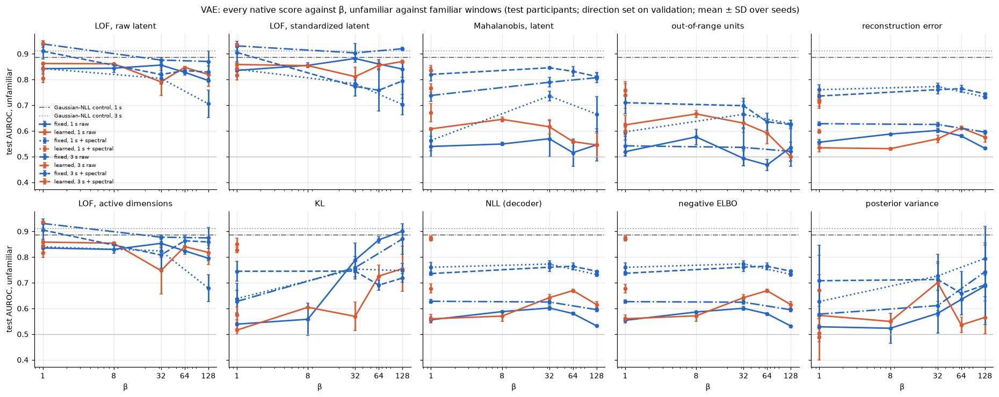

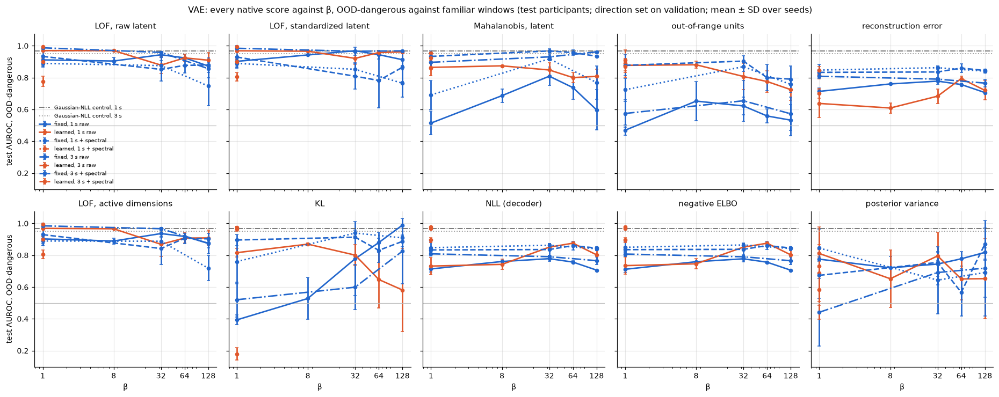

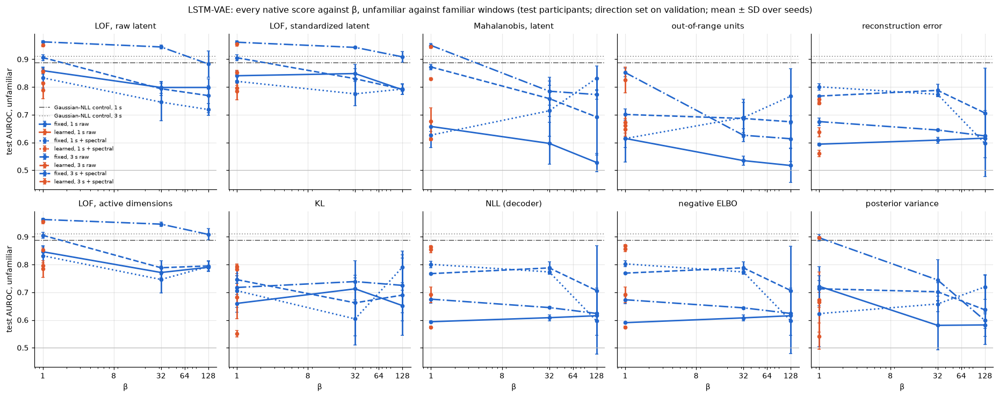

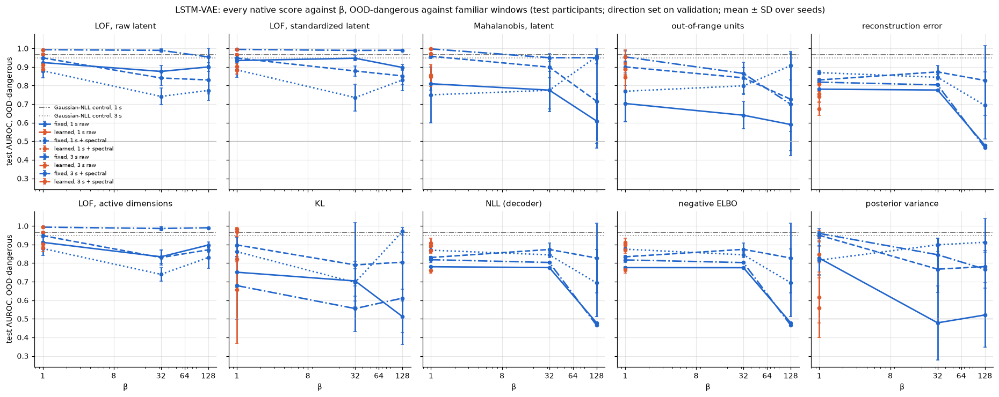

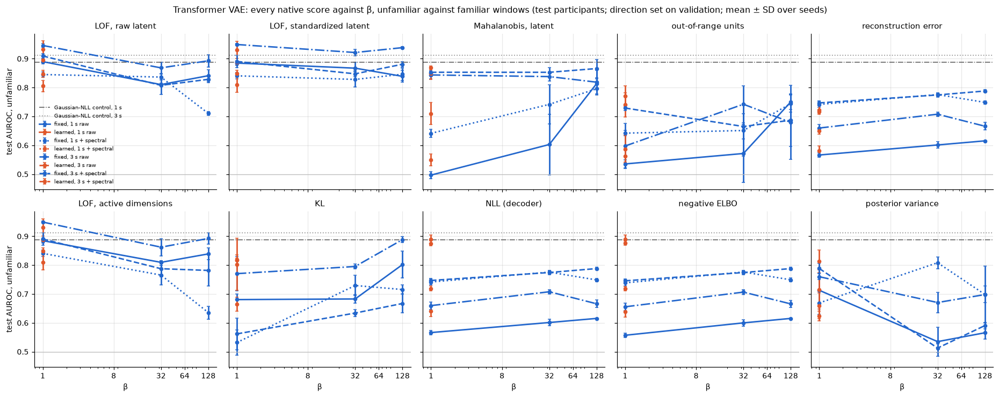

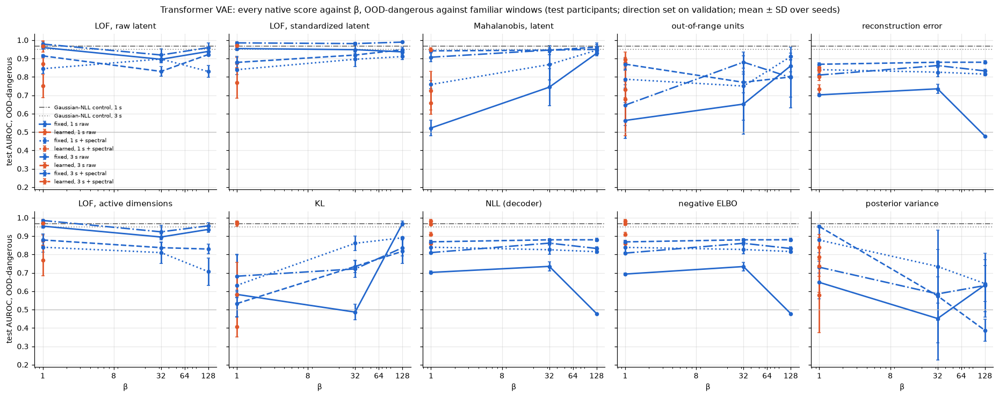

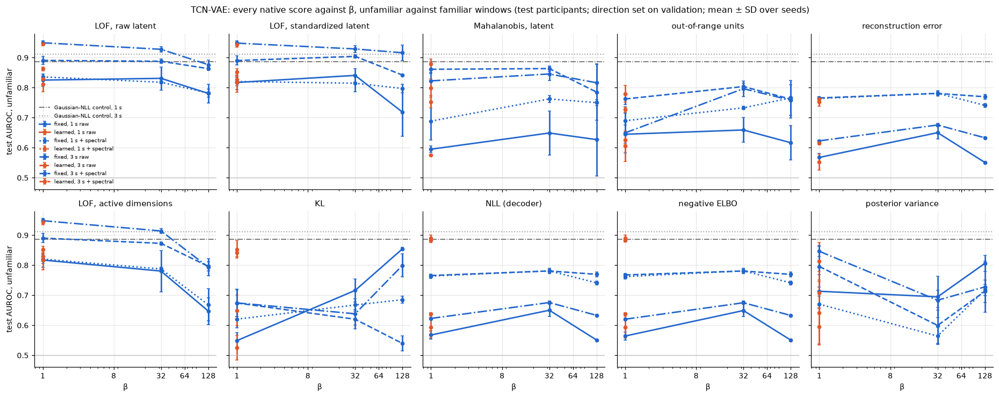

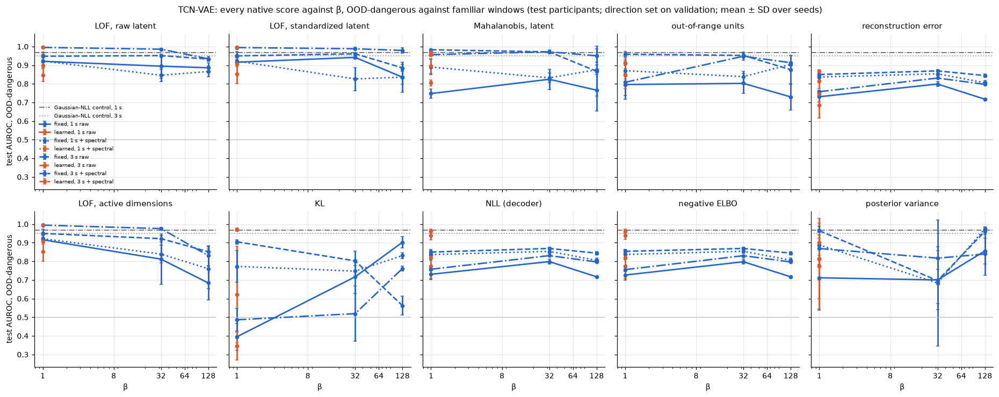

In [18]:
VAE_SCORES = ns.get_native_names('vae')
vae = native[native['family'] == 'vae'].join(SETUP[['arch', 'inputs', 'beta', 'variance']], on = 'model')
VARIANCE_C = {'fixed': '#2266cc', 'learned': '#e0572b'}                   # as notebook 02
INPUT_LS = {'raw_1s': '-', 'raw_1s_spectral': ':', 'raw_3s': '-.', 'raw_3s_spectral': '--'}
ARCH_TAG = {'conv': 'vae', 'lstm': 'lstm_vae', 'transformer': 'xformer_vae', 'tcn': 'tcn_vae'}
ref = native[native['score'] == 'LOF, raw latent'].groupby('model')[NATIVE_COLS].mean()
for arch in [a for a in ('conv', 'lstm', 'transformer', 'tcn') if a in set(vae['arch'])]:
    for col, what in (('AUROC, unfamiliar vs familiar', 'unfamiliar'), ('AUROC, OOD-dangerous vs familiar', 'OOD-dangerous')):
        fig, axes = plt.subplots(2, 5, figsize = (17, 6.8), sharex = True, sharey = True)
        for ax, score in zip(axes.flat, VAE_SCORES):
            part = vae[(vae['score'] == score) & (vae['arch'] == arch)]
            for (inputs, variance), sub in part.groupby(['inputs', 'variance']):
                stats = sub.groupby('beta')[f'test {col}'].agg(['mean', 'std'])
                ax.errorbar(stats.index, stats['mean'], yerr = stats['std'], color = VARIANCE_C[variance], ls = INPUT_LS[inputs], marker = 'o',
                            ms = 4, lw = 1.8, capsize = 2, label = f'{variance}, {ns.INPUT_LABELS[inputs]}')
            ax.axhline(ref.loc['gaussian · 1 s raw', f'test {col}'], color = '#555', ls = '-.', lw = 1, label = 'Gaussian-NLL control, 1 s')
            ax.axhline(ref.loc['gaussian · 3 s + spectral', f'test {col}'], color = '#999', ls = ':', lw = 1.2, label = 'Gaussian-NLL control, 3 s')
            ax.axhline(0.5, color = '#bbb', lw = .8)
            ax.set_xscale('log'); ax.set_xticks([1, 8, 32, 64, 128]); ax.get_xaxis().set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'))
            ax.set_title(score, fontsize = 9.5); ax.grid(alpha = .3)
        for ax in axes[1]:
            ax.set_xlabel('β')
        for ax in axes[:, 0]:
            ax.set_ylabel(f'test AUROC, {what}')
        axes[0, 0].legend(fontsize = 6.5, frameon = False, loc = 'lower left')
        fig.suptitle(f'{ns.ARCH_LABELS[arch]}: every native score against β, {what} against familiar windows '
                     '(test participants; direction set on validation; mean ± SD over seeds)', fontsize = 10.5)
        plt.tight_layout(); fig.savefig(FIG_DIR / f'05_{ARCH_TAG[arch]}_sweep_{what.lower().replace("-", "_")}.png', dpi = 160); plt.show()


### 7.4 What a downstream classifier could get from these scores

Two questions for the regime classifier (notebook 06). **Do the scores carry different information?** Rank correlation
between every pair of a model's native scores on the test windows (seed 0). **Does combining them help?** A logistic
regression on a model's scores, each mapped to a normal through its quantiles, trained to tell unfamiliar from familiar
windows on the validation participants and scored on the test participants (AUROC, mean over seeds), against the best
single score chosen on validation; and the same
classifier on pairs of scores taken from *different* models (the best single scores of each input), aligned window by window. Unlike every score above it is supervised with task labels, so it shows what the
scores can give a classifier trained on these tasks, not how a detector would meet a new kind of movement; holding out
whole tasks is notebook 06's test.

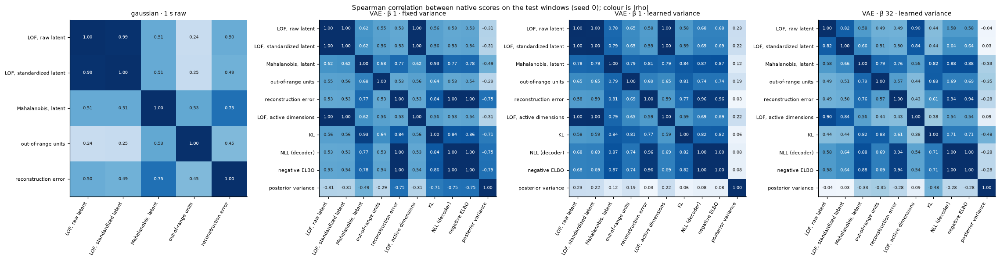

684 classifiers in 343 s; test AUROC, mean over seeds


,best single score,"single, unfamiliar","all native scores, unfamiliar","LOF + posterior uncertainty, unfamiliar","posterior uncertainty only, unfamiliar","single, OOD-dangerous","all native scores, OOD-dangerous"
model,,,,,,,
gaussian · 1 s raw,"LOF, raw latent",0.887,0.924,NaN,NaN,0.966,0.983
sparse · 1 s raw · λ 0.3,"LOF, raw latent",0.846,0.905,NaN,NaN,0.941,0.985
vanilla · 1 s raw,"LOF, raw latent",0.887,0.925,NaN,NaN,0.968,0.981
gaussian · 1 s + spectral,"LOF, raw latent",0.868,0.924,NaN,NaN,0.902,0.964
sparse · 1 s + spectral · λ 0.3,reconstruction error,0.762,0.874,NaN,NaN,0.871,0.923
...,...,...,...,...,...,...,...
Transformer VAE · β 1 · learned variance · 3 s raw,"LOF, raw latent",0.932,0.970,0.970,0.945,0.966,0.993
Transformer VAE · β 1 · fixed variance · 3 s + spectral,"LOF, raw latent",0.910,0.963,0.961,0.948,0.914,0.998
Transformer VAE · β 32 · fixed variance · 3 s + spectral,"Mahalanobis, latent",0.853,0.900,0.879,0.833,0.945,0.966


Across models (logistic regression on the pair, trained on validation, test AUROC, mean ± SD over seeds)


AUROC, unfamiliar vs familiar        AUROC, OOD-dangerous vs familiar       
                                                                             mean    std                             mean    std
pair                                                                                                                            
VAE β 128 fixed KL (1 s) + Gaussian-NLL LOF (1 s)                           0.933  0.003                            0.998  0.001
VAE β 128 fixed KL (1 s) + Gaussian-NLL LOF (3 s)                           0.950  0.003                            0.995  0.003
VAE β 128 fixed KL (1 s) + VAE β 128 fixed KL (3 s)                         0.909  0.005                            0.994  0.001
VAE β 128 fixed KL (3 s) + Gaussian-NLL LOF (3 s)                           0.914  0.013                            0.970  0.006

In [19]:
from scipy.stats import spearmanr

SHOWN_CORR = ['gaussian · 1 s raw', 'VAE · β 1 · fixed variance', 'VAE · β 1 · learned variance', 'VAE · β 32 · learned variance']
fig, axes = plt.subplots(1, len(SHOWN_CORR), figsize = (5.2 * len(SHOWN_CORR), 5.2))
for ax, model in zip(axes, SHOWN_CORR):
    r = with_val[(with_val['model'] == model) & (with_val['seed'] == 0)].iloc[0]
    names = ns.get_native_names(ns.get_family(r.config))
    rho = spearmanr(np.column_stack([native_scores[(r.run, n)][1] for n in names])).statistic
    im = ax.imshow(np.abs(rho), cmap = 'Blues', vmin = 0, vmax = 1)
    for i in range(len(names)):
        for j in range(len(names)):
            ax.text(j, i, f'{rho[i, j]:.2f}', ha = 'center', va = 'center', fontsize = 6.5, color = 'white' if abs(rho[i, j]) > .6 else '#222')
    ax.set_xticks(range(len(names)), names, rotation = 60, ha = 'right', fontsize = 7)
    ax.set_yticks(range(len(names)), names, fontsize = 7)
    ax.set_title(model, fontsize = 9)
fig.suptitle('Spearman correlation between native scores on the test windows (seed 0); colour is |rho|', fontsize = 10)
plt.tight_layout(); fig.savefig(FIG_DIR / '05_native_correlation.png', dpi = 160); plt.show()

FEATURE_SETS = {'all native scores': None, 'LOF + posterior uncertainty': ['LOF, raw latent', 'KL', 'posterior variance', 'NLL (decoder)'],
                'posterior uncertainty only': ['KL', 'posterior variance', 'NLL (decoder)', 'negative ELBO']}
SEEDS_N = sorted(native['seed'].unique())
t0 = time.time()
combo = []
for r in with_val.itertuples():
    family = ns.get_family(r.config)
    names = ns.get_native_names(family)
    labels_v, labels_t = val_labels[r.run], test_labels[r.run]
    lab_v = labels_v[pd.MultiIndex.from_frame(labels_v[['rec', 'end']]).isin(COMMON_VAL)].reset_index(drop = True)
    lab_t = labels_t[pd.MultiIndex.from_frame(labels_t[['rec', 'end']]).isin(COMMON)].reset_index(drop = True)
    for set_name, chosen_names in FEATURE_SETS.items():
        use = names if chosen_names is None else [n for n in chosen_names if n in names]
        if chosen_names is not None and len(use) < len(chosen_names):
            continue                                                      # a VAE-only set on an autoencoder
        fv = np.column_stack([native_scores[(r.run, n)][0] for n in use])
        ft = np.column_stack([native_scores[(r.run, n)][1] for n in use])
        combo.append({'model': r.model, 'seed': r.seed, 'features': set_name, **ns.get_combined_auroc(fv, lab_v, ft, lab_t, FAMILIAR)})
combo = pd.DataFrame(combo)
single = best.groupby('model')[['test AUROC, unfamiliar vs familiar', 'test AUROC, OOD-dangerous vs familiar']].mean()
combo_mean = combo.groupby(['model', 'features'])[['AUROC, unfamiliar vs familiar', 'AUROC, OOD-dangerous vs familiar']].mean().unstack()
summary_combo = pd.DataFrame({'best single score': best_score.reindex(MODELS_N),
                              'single, unfamiliar': single['test AUROC, unfamiliar vs familiar'].reindex(MODELS_N)})
for set_name in FEATURE_SETS:
    if ('AUROC, unfamiliar vs familiar', set_name) in combo_mean.columns:
        summary_combo[f'{set_name}, unfamiliar'] = combo_mean[('AUROC, unfamiliar vs familiar', set_name)].reindex(MODELS_N)
summary_combo['single, OOD-dangerous'] = single['test AUROC, OOD-dangerous vs familiar'].reindex(MODELS_N)
summary_combo['all native scores, OOD-dangerous'] = combo_mean[('AUROC, OOD-dangerous vs familiar', 'all native scores')].reindex(MODELS_N)
print(f'{len(combo)} classifiers in {time.time() - t0:.0f} s; test AUROC, mean over seeds')
display(summary_combo.round(3))

# across models: the best novelty score of one model with the LOF of another, aligned window by window
def get_aligned_scores(model: str, score: str, seed: int) -> tuple[pd.DataFrame, pd.DataFrame]:
    """(validation, test) frames of rec, end and one run's score, on the windows every run exported."""
    r = with_val[(with_val['model'] == model) & (with_val['seed'] == seed)].iloc[0]
    v, t = native_scores[(r.run, score)]
    lv_ = val_labels[r.run][pd.MultiIndex.from_frame(val_labels[r.run][['rec', 'end']]).isin(COMMON_VAL)].reset_index(drop = True)
    lt_ = test_labels[r.run][pd.MultiIndex.from_frame(test_labels[r.run][['rec', 'end']]).isin(COMMON)].reset_index(drop = True)
    return lv_.assign(s = v), lt_.assign(s = t)


PAIRS = {'VAE β 128 fixed KL (1 s) + Gaussian-NLL LOF (3 s)': [('VAE · β 128 · fixed variance', 'KL'), ('gaussian · 3 s + spectral', 'LOF, standardized latent')],
         'VAE β 128 fixed KL (1 s) + Gaussian-NLL LOF (1 s)': [('VAE · β 128 · fixed variance', 'KL'), ('gaussian · 1 s raw', 'LOF, raw latent')]}
if 'VAE · β 128 · fixed variance · 3 s + spectral' in set(native['model']):
    PAIRS['VAE β 128 fixed KL (1 s) + VAE β 128 fixed KL (3 s)'] = [('VAE · β 128 · fixed variance', 'KL'), ('VAE · β 128 · fixed variance · 3 s + spectral', 'KL')]
    PAIRS['VAE β 128 fixed KL (3 s) + Gaussian-NLL LOF (3 s)'] = [('VAE · β 128 · fixed variance · 3 s + spectral', 'KL'), ('gaussian · 3 s + spectral', 'LOF, standardized latent')]
cross = []
for pair, members in PAIRS.items():
    for seed in SEEDS_N:
        parts = [get_aligned_scores(m, s, seed) for m, s in members]
        cols = [f'score_{k}' for k in range(len(parts))]
        merged = []
        for split in (0, 1):
            frame = parts[0][split].rename(columns = {'s': cols[0]})
            for k in range(1, len(parts)):
                frame = frame.merge(parts[k][split][['rec', 'end', 's']].rename(columns = {'s': cols[k]}), on = ['rec', 'end'])
            merged.append(frame)
        v, t = merged
        cross.append({'pair': pair, 'seed': seed, **ns.get_combined_auroc(v[cols].to_numpy(), v, t[cols].to_numpy(), t, FAMILIAR)})
cross = pd.DataFrame(cross)
print('Across models (logistic regression on the pair, trained on validation, test AUROC, mean ± SD over seeds)')
display(cross.groupby('pair')[['AUROC, unfamiliar vs familiar', 'AUROC, OOD-dangerous vs familiar']].agg(['mean', 'std']).round(3))


### 7.5 What changed

- **The VAE's KL at high β is the best single novelty score on 1 s windows, and it points down.** At β 128 with the
  variance fixed, a *lower* KL means unfamiliar: test AUROC 0.901 ± 0.004 (validation 0.886, where it was chosen) and
  0.989 ± 0.003 for the OOD-dangerous tasks. At the 1% target it flags 53% of unfamiliar and 85% of OOD-dangerous test
  windows at 1.7% false alarms, against 34% and 48% at 2.0% for the Gaussian-NLL control. The signal appears only once
  β prunes the code (KL is at chance at β 1 and 8, 0.79 at β 32, 0.87 at β 64): with one filter left, the encoder spends
  its KL on what familiar movement has in common, and an unfamiliar window leaves the posterior nearer the prior. With
  the learned variance the same score is weaker (0.73 to 0.76).
- **LOF on the posterior means never beats the control.** Its best is 0.88 (β 32, fixed, standardized), as in the
  Science Robotics study.
- **The learned variance at low β ranks the dangerous tasks well.** LOF on its posterior means reaches 0.970 for
  OOD-dangerous windows at β 1 and 8 and flags 74 to 78% of them, at 2.5% false alarms and 0.86 for all unfamiliar tasks.
- **The likelihood and width scores are weak.** Decoder NLL, negative ELBO and reconstruction error stay at 0.53 to 0.67,
  posterior variance at 0.52 to 0.70 in either direction: the posterior's width is not where the VAE's uncertainty about
  unfamiliar movement shows; its distance from the prior is, at high β.
- **The generic scores are weak on 1 s latents.** Mahalanobis distance and out-of-range units stay at 0.47 to 0.67 there
  (0.62 to 0.85 on 3 s latents). The label-free out-of-range score does not reproduce the sparse model's novelty units
  (0.51 to 0.62), which notebook 01 found with task labels.
- **For a downstream classifier the scores combine.** Trained on the validation participants with task labels, a model's
  native scores together add 0.03 to 0.09 AUROC over its best single score for most models (Gaussian-NLL 1 s 0.887 to
  0.924; VAE β 32 to 128 with fixed variance 0.927 to 0.929; OOD-dangerous up to 0.998), and nothing for the 3 s
  Gaussian-NLL latent (0.914 to 0.910). The VAE's uncertainty scores alone (KL, NLL, ELBO, posterior variance) give 0.62
  to 0.75 at β 1 to 8 and 0.87 to 0.92 at β 32 to 128, so they carry information a classifier can use only once β prunes
  the code. These classifiers saw the unfamiliar tasks in training; notebook 06 has to hold out whole tasks.

**With the 3 s + spectral VAE cells** (β 1, 32, 64, 128 fixed; β 1 learned; three seeds each):

- **The KL effect does not carry over to 3 s inputs.** On 3 s windows β prunes less (18, 13 and 14 active dimensions at
  β 32, 64 and 128, against 8 on 1 s), the KL reads *upwards* there and stays at 0.69 to 0.75. The downward KL detector
  is specific to the 1 s VAE at high β. *Correction from section 9: it is the spectral features, not the 3 s window,
  that turn the KL upward; on 3 s raw windows it reads downward again (0.87 at β 128, 0.89 for the Transformer VAE).*
- **The best 3 s VAE is the plain one.** At β 1 with fixed variance, LOF on its posterior means reaches 0.910 ± 0.030
  (validation 0.882), level with the 3 s Gaussian-NLL control (0.914), but 0.934 for the OOD-dangerous tasks.
- **With the learned variance, the 3 s VAE's likelihood works.** Decoder NLL and negative ELBO reach 0.876 (0.56 on 1 s
  windows) and 0.977 for the OOD-dangerous tasks, flagging 56% of unfamiliar and 83% of OOD-dangerous windows, but at
  3.9% false alarms on test against the 1% target: its familiar score level moves the most between people.
- **Across models, the best pair is the 1 s VAE's KL with the 3 s Gaussian-NLL control's LOF**: 0.950 ± 0.003 for
  unfamiliar and 0.995 for OOD-dangerous windows (supervised on the validation participants, as in 7.4). The two 1 s
  scores together give 0.933 / 0.998, the 1 s and 3 s KL together 0.909, the 3 s KL with the 3 s LOF 0.914: the gain
  comes from pairing the 1 s KL with a 3 s latent, two different views of the movement.

## 8. Onset latency: how soon after a movement starts the alarm fires

A detector that flags 50% of an unfamiliar task's windows may still flag the task late. For the controller what matters
is the time from the start of an unfamiliar movement to the first alarm, and the share of movements never flagged. A
*bout* is a run of consecutive in-task windows of one recording (at least 2 s long); its latency is the time from its
first window to its first flagged window, with each model's best score (7.2) at its validation threshold (1% false alarms,
after the 0.5 s causal median, so the filter's delay is included). Longer windows see more of the past: a 3 s window at
the start of a bout is still mostly what came before, which is the cost this section measures. Familiar bouts are listed
too: the share of them that raise any alarm is the controller's false-switch rate per movement.
The figure draws the Gaussian-NLL control on both inputs and the best model of each VAE architecture (chosen on validation
by 7.2's rule); every model is in the table.

In [20]:
t0 = time.time()
bouts = []
for r in with_val.itertuples():
    score = best_score[r.model]
    labels_t = test_labels[r.run]
    keep_t = pd.MultiIndex.from_frame(labels_t[['rec', 'end']]).isin(COMMON)
    lab_t = labels_t[keep_t].reset_index(drop = True)
    v, t = native_scores[(r.run, score)]
    m = native[(native['model'] == r.model) & (native['seed'] == r.seed) & (native['score'] == score)].iloc[0]
    flagged = ns.get_filtered(m['sign'] * t, lab_t) > m['threshold']
    b = ns.get_onset_latency(flagged, lab_t)
    bouts.append(b.assign(model = r.model, seed = r.seed, score = score))
bouts = pd.concat(bouts, ignore_index = True)
bouts['kind'] = np.where(bouts['task'].isin(FAMILIAR), 'familiar', np.where(bouts['controller_class'] == 'OOD-dangerous', 'OOD-dangerous', 'OOD-safe'))
bouts['unfamiliar'] = bouts['kind'] != 'familiar'


def summarize_latency(frame: pd.DataFrame) -> pd.Series:
    """Share of bouts flagged at all, and the median and 90th percentile latency of those flagged."""
    hit = frame['latency_s'].notna()
    return pd.Series({'bouts': len(frame), 'flagged (%)': 100 * hit.mean(), 'median latency (s)': frame.loc[hit, 'latency_s'].median(),
                      '90th pct latency (s)': frame.loc[hit, 'latency_s'].quantile(.9)})


lat = bouts.groupby(['model', 'seed', 'kind']).apply(summarize_latency).reset_index()
lat_mean = lat.groupby(['model', 'kind'])[['bouts', 'flagged (%)', 'median latency (s)', '90th pct latency (s)']].mean().unstack('kind')
order = [m for m in MODELS_N if m in lat_mean.index]
show = pd.DataFrame({'best score': best_score.reindex(order)})
for kind in ('OOD-dangerous', 'OOD-safe', 'familiar'):
    show[f'{kind}: bouts flagged (%)'] = lat_mean[('flagged (%)', kind)].reindex(order)
    if kind != 'familiar':
        show[f'{kind}: median latency (s)'] = lat_mean[('median latency (s)', kind)].reindex(order)
print(f'{bouts.groupby(["model", "seed"]).size().iloc[0]} test bouts per run; {time.time() - t0:.0f} s. Mean over seeds.')
display(show.round(2))

571 test bouts per run; 40 s. Mean over seeds.


,best score,OOD-dangerous: bouts flagged (%),OOD-dangerous: median latency (s),OOD-safe: bouts flagged (%),OOD-safe: median latency (s),familiar: bouts flagged (%)
model,,,,,,
gaussian · 1 s raw,"LOF, raw latent",87.18,2.31,72.90,0.76,6.06
sparse · 1 s raw · λ 0.3,"LOF, raw latent",79.49,2.75,63.62,0.86,6.06
vanilla · 1 s raw,"LOF, raw latent",89.74,1.84,70.26,0.92,5.05
gaussian · 1 s + spectral,"LOF, raw latent",82.05,1.60,74.05,0.33,11.11
sparse · 1 s + spectral · λ 0.3,reconstruction error,69.23,2.42,46.75,1.33,8.59
...,...,...,...,...,...,...
Transformer VAE · β 1 · learned variance · 3 s raw,"LOF, raw latent",89.74,0.30,82.99,0.00,6.06
Transformer VAE · β 1 · fixed variance · 3 s + spectral,"LOF, raw latent",43.59,0.32,77.30,0.00,13.64
Transformer VAE · β 32 · fixed variance · 3 s + spectral,"Mahalanobis, latent",87.18,0.45,77.37,0.13,15.66


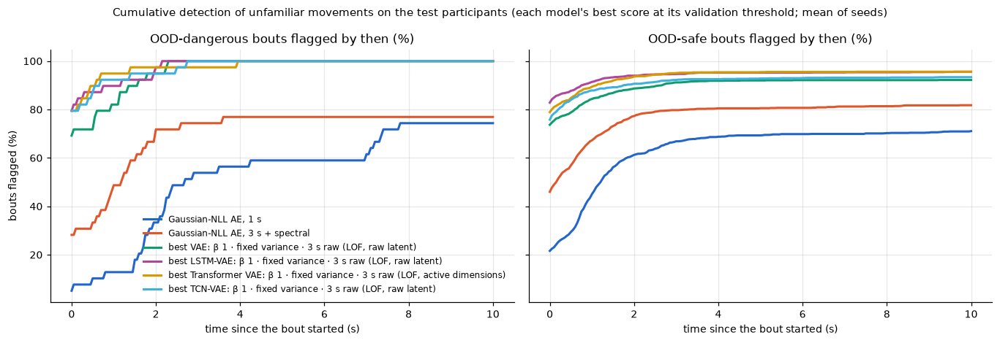

task,ball_toss,sit_to_stand,tug_of_war
model,,,
"Gaussian-NLL AE, 1 s",0.65,1.85,7.35
"Gaussian-NLL AE, 3 s + spectral",NaN,1.35,0.60
"best VAE: β 1 · fixed variance · 3 s raw (LOF, raw latent)",0.00,0.00,0.00
"best LSTM-VAE: β 1 · fixed variance · 3 s raw (LOF, raw latent)",0.00,0.00,0.00
"best Transformer VAE: β 1 · fixed variance · 3 s raw (LOF, active dimensions)",0.00,0.00,0.00
"best TCN-VAE: β 1 · fixed variance · 3 s raw (LOF, raw latent)",0.00,0.00,0.00


In [21]:
def get_best_model(models: list[str]) -> str:
    """The model whose best score has the highest validation AUROC (7.2's rule)."""
    return max(models, key = lambda m: native[(native['model'] == m) & (native['score'] == best_score[m])]['val AUROC, unfamiliar vs familiar'].mean())


SHOWN_LAT = {'Gaussian-NLL AE, 1 s': 'gaussian · 1 s raw', 'Gaussian-NLL AE, 3 s + spectral': 'gaussian · 3 s + spectral'}
for arch in ('conv', 'lstm', 'transformer', 'tcn'):
    members = [m for m in order if SETUP.loc[m, 'arch'] == arch]
    if members:
        pick = get_best_model(members)
        SHOWN_LAT[f'best {ns.ARCH_LABELS[arch]}: {pick.split(" · ", 1)[1]} ({best_score[pick]})'] = pick
LAT_C = dict(zip(SHOWN_LAT, ['#2266cc', '#e0572b', '#0f9d6e', '#b0479a', '#d99a00', '#3fb0e0']))   # validated palette slots, fixed order
grid_s = np.linspace(0, 10, 201)
fig, axes = plt.subplots(1, 2, figsize = (12.5, 4.3), sharey = True)
for ax, kind in zip(axes, ('OOD-dangerous', 'OOD-safe')):
    for name, model in SHOWN_LAT.items():
        part = bouts[(bouts['model'] == model) & (bouts['kind'] == kind)]
        curve = np.mean([[(sub['latency_s'] <= x).mean() * 100 for x in grid_s] for _, sub in part.groupby('seed')], axis = 0)
        ax.plot(grid_s, curve, color = LAT_C[name], lw = 2, label = name)
    ax.set(xlabel = 'time since the bout started (s)', title = f'{kind} bouts flagged by then (%)'); ax.grid(alpha = .3)
axes[0].set_ylabel('bouts flagged (%)'); axes[0].legend(fontsize = 8, frameon = False, loc = 'lower right')
fig.suptitle('Cumulative detection of unfamiliar movements on the test participants (each model\'s best score at its validation threshold; mean of seeds)', fontsize = 10)
plt.tight_layout(); fig.savefig(FIG_DIR / '05_onset_latency.png', dpi = 160); plt.show()

per_task_lat = (bouts[(bouts['kind'] == 'OOD-dangerous') & bouts['model'].isin(SHOWN_LAT.values())]
                .groupby(['model', 'task'])['latency_s'].agg(lambda x: x.median() if x.notna().any() else np.nan).unstack())
display(per_task_lat.reindex(list(SHOWN_LAT.values())).round(2).rename(index = {v: k for k, v in SHOWN_LAT.items()}))

### 8.1 What this shows

Test participants, 13 OOD-dangerous and about 120 OOD-safe bouts per run, means over seeds; the bouts start on the same
windows for every model (those with 3 s of clean history), so 1 s and 3 s models are compared on equal terms.

- **The 3 s raw VAEs catch every OOD-dangerous movement at once.** The best conv, LSTM and Transformer VAEs (all β 1,
  fixed variance, 3 s raw) flag every dangerous bout, half of them on its first window (median latency 0 s for the ball
  toss, sit-to-stand and tug of war alike), and 94 to 96% of OOD-safe bouts. The 1 s Gaussian-NLL control eventually
  flags 87% of the dangerous bouts, half only after 2.3 s (tug of war 7.4 s).
- **Correction to the earlier reading: the familiar false switches came from the spectral features, not the 3 s
  window.** With spectral features, 3 s models raise an alarm somewhere in 11 to 15% of familiar bouts (the LSTM-VAE 7%);
  the same models on 3 s raw do so in 4 to 6%, as few as the 1 s autoencoders (5 to 6%). An earlier version of this section attributed the
  cost to the window's length (section 9.3 has every model type on every input).
- **Recall per movement is far higher than recall per window.** The 1 s control flags 34% of unfamiliar windows but
  73% of unfamiliar movements, so the per-window figures of sections 3 to 7 understate what a controller sees.
- With 13 dangerous bouts per run the shares move in steps of about 8 points; differences of one bout should not be read.

## 9. The full comparison: every model type on every input

Six model types (plain, sparse and Gaussian-NLL autoencoders; conv, LSTM and Transformer VAEs) on the four inputs of the
2 x 2 ablation (window 1 s or 3 s, with or without the seven spectral features). Within each (type, input) the cell and
the score are chosen on the validation participants by 7.2's rule (the best validation AUROC for unfamiliar against
familiar windows over every cell and native score), then reported on the test participants. The plain and sparse AE
include the λ 0.1 and 8 x 4 variants where they exist; the VAEs include every β and decoder variance trained on that input.

model (cell)                     score validation AUROC, unfamiliar vs familiar AUROC, unfamiliar vs familiar  \
type            input                                                                                                                                                                        
plain AE        1 s raw                                                 vanilla · 1 s raw           LOF, raw latent                            0.867 ± 0.013                 0.887 ± 0.010   
                1 s + spectral                                   vanilla · 1 s + spectral  LOF, standardized latent                            0.837 ± 0.007                 0.878 ± 0.007   
                3 s raw                                                 vanilla · 3 s raw           LOF, raw latent                            0.929 ± 0.009                 0.950 ± 0.006   
                3 s + spectral                                   vanilla · 3 s + spectral           LOF, raw latent                            0.864 ± 0.008                 0.893 ± 0.010   
sparse AE       1 s raw                                          sparse · 1 s raw · λ 0.3           LOF, raw latent                            0.830 ± 0.012                 0.846 ± 0.011   
                1 s + spectral                            sparse · 1 s + spectral · λ 0.3      reconstruction error                            0.750 ± 0.011                 0.762 ± 0.014   
                3 s raw                                          sparse · 3 s raw · λ 0.3           LOF, raw latent                            0.888 ± 0.019                 0.907 ± 0.016   
                3 s + spectral                            sparse · 3 s + spectral · λ 0.1           LOF, raw latent                            0.804 ± 0.028                 0.811 ± 0.018   
Gaussian-NLL AE 1 s raw                                                gaussian · 1 s raw           LOF, raw latent                            0.865 ± 0.008                 0.887 ± 0.014   
                1 s + spectral                                  gaussian · 1 s + spectral           LOF, raw latent                            0.837 ± 0.013                 0.868 ± 0.016   
                3 s raw                                                gaussian · 3 s raw           LOF, raw latent                            0.926 ± 0.005                 0.943 ± 0.008   
                3 s + spectral                                  gaussian · 3 s + spectral  LOF, standardized latent                            0.890 ± 0.013                 0.914 ± 0.013   
conv VAE        1 s raw                                      VAE · β 128 · fixed variance                        KL                            0.886 ± 0.005                 0.901 ± 0.004   
                1 s + spectral              VAE · β 1 · learned variance · 1 s + spectral             negative ELBO                            0.847 ± 0.002                 0.869 ± 0.004   
                3 s raw                              VAE · β 1 · fixed variance · 3 s raw           LOF, raw latent                            0.922 ± 0.008                 0.939 ± 0.013   
                3 s + spectral                VAE · β 1 · fixed variance · 3 s + spectral           LOF, raw latent                            0.882 ± 0.023                 0.910 ± 0.030   
LSTM-VAE        1 s raw                                   LSTM-VAE · β 1 · fixed variance           LOF, raw latent                            0.845 ± 0.006                 0.859 ± 0.013   
                1 s + spectral         LSTM-VAE · β 1 · learned variance · 1 s + spectral             negative ELBO                            0.849 ± 0.002                 0.868 ± 0.003   
                3 s raw                         LSTM-VAE · β 1 · fixed variance · 3 s raw           LOF, raw latent                            0.945 ± 0.014                 0.963 ± 0.004   
                3 s + spectral           LSTM-VAE · β 1 · fixed variance · 3 s + spectr

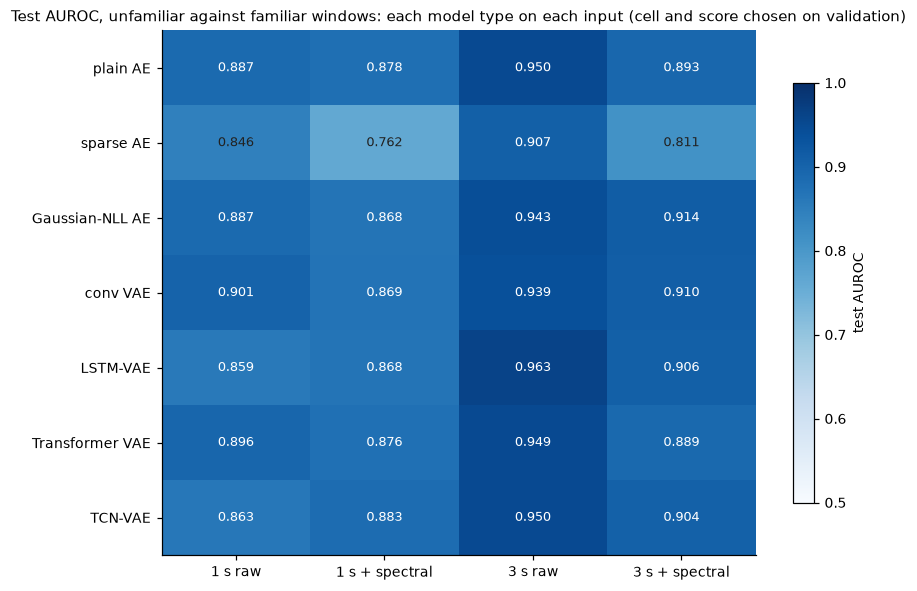

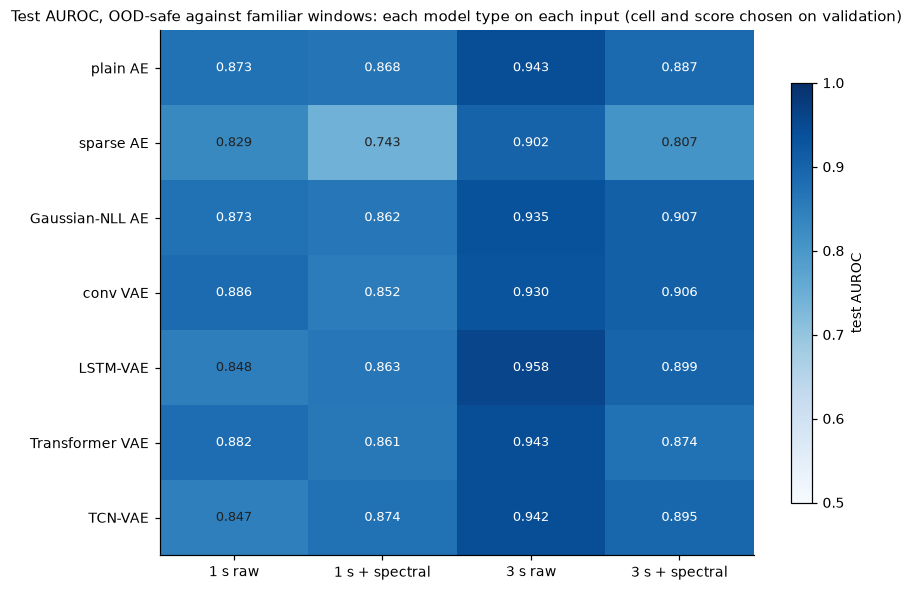

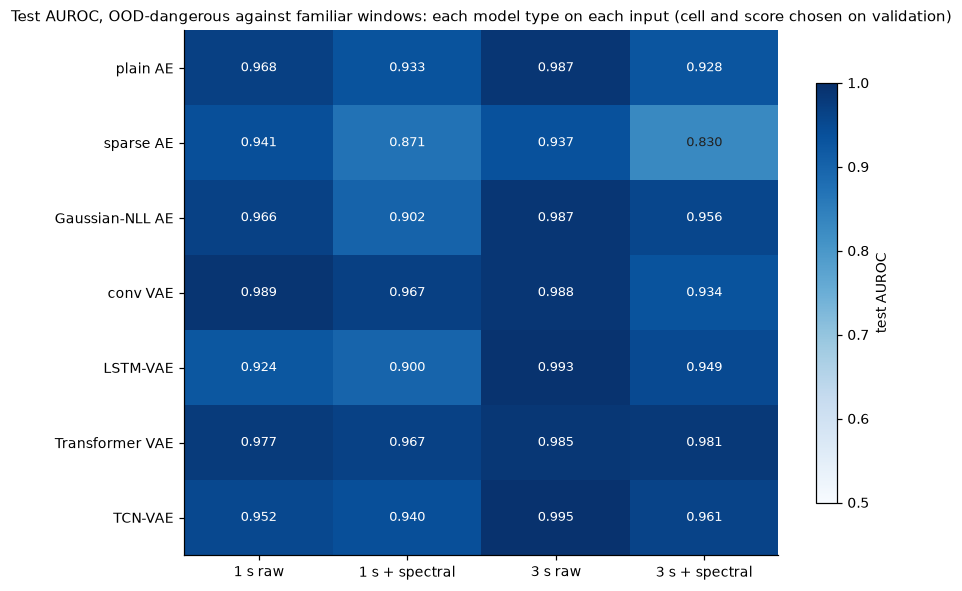

In [22]:
TYPES = [t for t in ns.MODEL_TYPES if t in set(SETUP['type'])]
INPUTS_SHOWN = [ns.INPUT_LABELS[k] for k in ns.INPUT_ORDER if k in set(SETUP['inputs'])]
nat = native.join(SETUP[['type', 'input']], on = 'model')
cell_mean = nat.groupby(['type', 'input', 'model', 'score'])[NATIVE_COLS].mean()
chosen_setup = cell_mean['val AUROC, unfamiliar vs familiar'].groupby(['type', 'input']).idxmax()       # -> (type, input, model, score)
rows = []
for (tp, inp), key in chosen_setup.items():
    model, score = key[2], key[3]
    sub = nat[(nat['model'] == model) & (nat['score'] == score)]
    rows.append({'type': tp, 'input': inp, 'model': model, 'score': score,
                 **{f'{c} mean': sub[c].mean() for c in NATIVE_COLS}, **{f'{c} sd': sub[c].std() for c in NATIVE_COLS}})
full = pd.DataFrame(rows).set_index(['type', 'input']).reindex(pd.MultiIndex.from_product([TYPES, INPUTS_SHOWN], names = ['type', 'input']))
show_full = pd.DataFrame({'model (cell)': full['model'], 'score': full['score']})
for c in NATIVE_COLS:
    f = '{:.3f}' if 'AUROC' in c else '{:.1f}'
    show_full[c.replace('test ', '').replace('val ', 'validation ')] = full[f'{c} mean'].map(f.format) + ' ± ' + full[f'{c} sd'].map(f.format)
display(show_full)


def plot_type_input(values: pd.DataFrame, title: str, label: str, path: Path, fmt: str = '{:.3f}', vmin: float = .5, vmax: float = 1.0) -> None:
    """Model types (rows) x inputs (columns), annotated."""
    fig, ax = plt.subplots(figsize = (8.2, 0.55 * len(values) + 1.6))
    im = ax.imshow(values.to_numpy(dtype = float), aspect = 'auto', cmap = 'Blues', vmin = vmin, vmax = vmax)
    for r in range(values.shape[0]):
        for k in range(values.shape[1]):
            v = values.iat[r, k]
            if np.isfinite(v):
                ax.text(k, r, fmt.format(v), ha = 'center', va = 'center', fontsize = 8.5, color = 'white' if v > vmin + .7 * (vmax - vmin) else '#222')
    ax.set_xticks(range(values.shape[1]), values.columns); ax.set_yticks(range(values.shape[0]), values.index)
    ax.set_title(title, fontsize = 9.5); fig.colorbar(im, ax = ax, shrink = .8, label = label); plt.tight_layout()
    fig.savefig(path, dpi = 160); plt.show()


for c, what in (('test AUROC, unfamiliar vs familiar', 'unfamiliar'), ('test AUROC, OOD-safe vs familiar', 'OOD-safe'), ('test AUROC, OOD-dangerous vs familiar', 'OOD-dangerous')):
    grid = full[f'{c} mean'].unstack('input').reindex(index = TYPES, columns = INPUTS_SHOWN)
    plot_type_input(grid, f'Test AUROC, {what} against familiar windows: each model type on each input (cell and score chosen on validation)',
                    'test AUROC', FIG_DIR / f'05_full_{what.lower().replace("-", "_")}.png')

### 9.1 Every metric on every set-up

For each native score and each (type, input), the best cell for that score on validation, its test AUROC for unfamiliar
windows. Blank where a score does not belong to the model type (the VAE scores for the autoencoders).

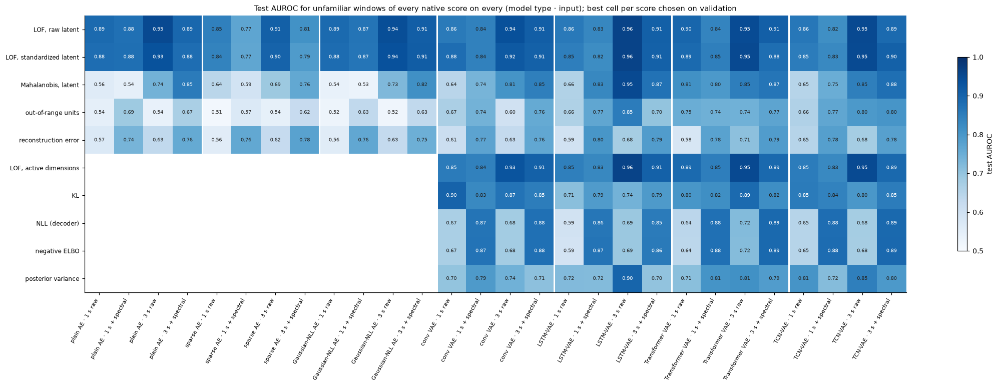

In [23]:
per_score = cell_mean['val AUROC, unfamiliar vs familiar'].groupby(['type', 'input', 'score']).idxmax()
metric_grid = pd.Series({(k[2], f'{k[0]} · {k[1]}'): cell_mean.loc[key, 'test AUROC, unfamiliar vs familiar'] for k, key in per_score.items()}).unstack()
cols = [f'{t} · {i}' for t in TYPES for i in INPUTS_SHOWN if f'{t} · {i}' in metric_grid.columns]
metric_grid = metric_grid.reindex(index = NATIVE_ORDER, columns = cols)
fig, ax = plt.subplots(figsize = (0.62 * len(cols) + 3, 0.45 * len(NATIVE_ORDER) + 2.6))
im = ax.imshow(metric_grid.to_numpy(dtype = float), aspect = 'auto', cmap = 'Blues', vmin = .5, vmax = 1.0)
for r in range(metric_grid.shape[0]):
    for k in range(metric_grid.shape[1]):
        v = metric_grid.iat[r, k]
        if np.isfinite(v):
            ax.text(k, r, f'{v:.2f}', ha = 'center', va = 'center', fontsize = 6.5, color = 'white' if v > .85 else '#222')
ax.set_xticks(range(len(cols)), cols, rotation = 60, ha = 'right', fontsize = 7.5); ax.set_yticks(range(len(NATIVE_ORDER)), NATIVE_ORDER, fontsize = 8)
for e in np.arange(len(INPUTS_SHOWN), len(cols), len(INPUTS_SHOWN)) - .5:
    ax.axvline(e, color = 'w', lw = 2)
ax.set_title('Test AUROC for unfamiliar windows of every native score on every (model type · input); best cell per score chosen on validation', fontsize = 9.5)
fig.colorbar(im, ax = ax, shrink = .7, label = 'test AUROC'); plt.tight_layout(); fig.savefig(FIG_DIR / '05_full_metric_by_setup.png', dpi = 160); plt.show()

### 9.2 What each half of the input ablation does

Differences in the chosen test AUROC (9.0) between inputs, per model type: adding the spectral features at each window
length, and lengthening the window with and without them. Positive means the change helped.

In [24]:
def get_delta(col: str, a: str, b: str) -> pd.Series:
    """Test AUROC of input ``b`` minus input ``a``, per model type (NaN where either is missing)."""
    vals = full[f'{col} mean'].unstack('input')
    return (vals.get(b) - vals.get(a)).reindex(TYPES) if a in vals and b in vals else pd.Series(np.nan, index = TYPES)


CONTRASTS = {'+ spectral, 1 s': ('1 s raw', '1 s + spectral'), '+ spectral, 3 s': ('3 s raw', '3 s + spectral'),
             '1 s → 3 s, raw': ('1 s raw', '3 s raw'), '1 s → 3 s, + spectral': ('1 s + spectral', '3 s + spectral')}
deltas = pd.concat({what: pd.DataFrame({name: get_delta(c, a, b) for name, (a, b) in CONTRASTS.items()})
                    for c, what in (('test AUROC, unfamiliar vs familiar', 'unfamiliar'), ('test AUROC, OOD-dangerous vs familiar', 'OOD-dangerous'))}, axis = 1)
display(deltas.round(3))

unfamiliar                                                        OOD-dangerous                                                     
                + spectral, 1 s + spectral, 3 s 1 s → 3 s, raw 1 s → 3 s, + spectral + spectral, 1 s + spectral, 3 s 1 s → 3 s, raw 1 s → 3 s, + spectral
type                                                                                                                                                     
plain AE                 -0.009          -0.056          0.062                 0.015          -0.034          -0.059          0.020                -0.005
sparse AE                -0.084          -0.096          0.061                 0.049          -0.070          -0.107         -0.004                -0.042
Gaussian-NLL AE          -0.019          -0.029          0.056                 0.046          -0.065          -0.031          0.020                 0.054
conv VAE                 -0.032          -0.028          0.037                 0.041          -0.022          -0.054         -0.002                -0.034
LSTM-VAE                  0.009          -0.057          0.104                 0.038          -0.024          -0.044          0.069                 0.049
Transformer VAE          -0.020          -0.060          0.054                 0.013          -0.010          -0.004          0.008                 0.014
TCN-VAE                   0.021          -0.045          0.087                 0.021          -0.012          -0.034          0.043                 0.021

### 9.3 Per movement: each set-up as an alarm

From section 8's bouts, for the cell chosen in 9.0: the share of OOD-dangerous movements flagged and their median
latency, the share of OOD-safe movements flagged, and the share of familiar movements that raise any alarm (the
false-switch rate). Means over seeds.

model (cell)                     score  dangerous movements flagged (%)  dangerous median latency (s)  \
type            input                                                                                                                                                                
plain AE        1 s raw                                                 vanilla · 1 s raw           LOF, raw latent                            89.74                          1.84   
                1 s + spectral                                   vanilla · 1 s + spectral  LOF, standardized latent                            87.18                          1.70   
                3 s raw                                                 vanilla · 3 s raw           LOF, raw latent                            89.74                          0.27   
                3 s + spectral                                   vanilla · 3 s + spectral           LOF, raw latent                            64.10                          0.36   
sparse AE       1 s raw                                          sparse · 1 s raw · λ 0.3           LOF, raw latent                            79.49                          2.75   
                1 s + spectral                            sparse · 1 s + spectral · λ 0.3      reconstruction error                            69.23                          2.42   
                3 s raw                                          sparse · 3 s raw · λ 0.3           LOF, raw latent                            61.54                          2.48   
                3 s + spectral                            sparse · 3 s + spectral · λ 0.1           LOF, raw latent                            94.87                          1.15   
Gaussian-NLL AE 1 s raw                                                gaussian · 1 s raw           LOF, raw latent                            87.18                          2.31   
                1 s + spectral                                  gaussian · 1 s + spectral           LOF, raw latent                            82.05                          1.60   
                3 s raw                                                gaussian · 3 s raw           LOF, raw latent                           100.00                          0.27   
                3 s + spectral                                  gaussian · 3 s + spectral  LOF, standardized latent                            76.92                          0.57   
conv VAE        1 s raw                                      VAE · β 128 · fixed variance                        KL                           100.00                          0.17   
                1 s + spectral              VAE · β 1 · learned variance · 1 s + spectral             negative ELBO                           100.00                          0.63   
                3 s raw                              VAE · β 1 · fixed variance · 3 s raw           LOF, raw latent                           100.00                          0.00   
                3 s + spectral                VAE · β 1 · fixed variance · 3 s + spectral           LOF, raw latent                            71.79                          0.36   
LSTM-VAE        1 s raw                                   LSTM-VAE · β 1 · fixed variance           LOF, raw latent                            92.31                          1.10   
                1 s + spectral         LSTM-VAE · β 1 · learned variance · 1 s + spectral             negative ELBO                            89.74                          1.50   
                3 s raw                         LSTM-VAE · β 1 · fixed variance · 3 s raw           LOF, raw latent                           100.00                          0.00   
                3 s + spectral           LSTM-VAE · β 1 · fixed variance · 3 s + spectral           LOF, raw latent                            38.46                          0.45   
Transformer VAE 1 s raw                          Transformer VAE · β 1 · 

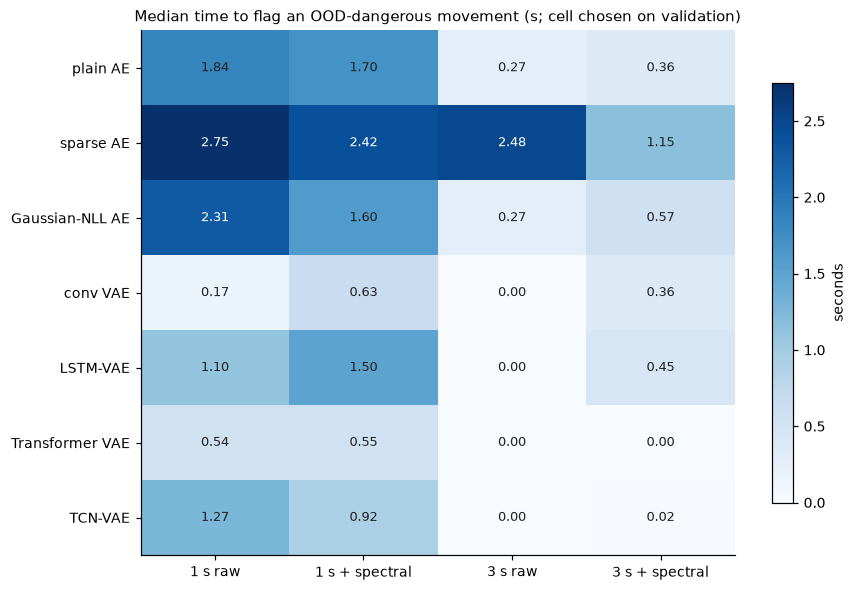

In [25]:
lat_all = bouts.groupby(['model', 'seed', 'kind']).apply(summarize_latency).reset_index().groupby(['model', 'kind'])[
    ['flagged (%)', 'median latency (s)']].mean().unstack('kind')
alarm = pd.DataFrame({'model (cell)': full['model'], 'score': full['score']})
alarm['dangerous movements flagged (%)'] = [lat_all.loc[m, ('flagged (%)', 'OOD-dangerous')] if isinstance(m, str) else np.nan for m in full['model']]
alarm['dangerous median latency (s)'] = [lat_all.loc[m, ('median latency (s)', 'OOD-dangerous')] if isinstance(m, str) else np.nan for m in full['model']]
alarm['OOD-safe movements flagged (%)'] = [lat_all.loc[m, ('flagged (%)', 'OOD-safe')] if isinstance(m, str) else np.nan for m in full['model']]
alarm['familiar movements alarmed (%)'] = [lat_all.loc[m, ('flagged (%)', 'familiar')] if isinstance(m, str) else np.nan for m in full['model']]
display(alarm.round(2))
plot_type_input(alarm['dangerous median latency (s)'].unstack('input').reindex(index = TYPES, columns = INPUTS_SHOWN),
                'Median time to flag an OOD-dangerous movement (s; cell chosen on validation)', 'seconds', FIG_DIR / '05_full_latency.png',
                fmt = '{:.2f}', vmin = 0, vmax = float(np.nanmax(alarm['dangerous median latency (s)'])))

### 9.4 Latent to latent: how similar are the representations?

Linear centred kernel alignment (CKA) between the latents of every (type, input), for the cell chosen in 9.0, seed 0, on
the same 4,000 test windows (posterior means for the VAEs). CKA is 1 when one latent is a rotation and rescaling of the
other and near 0 when they share no linear structure; it compares what the latents encode, not how well they detect.

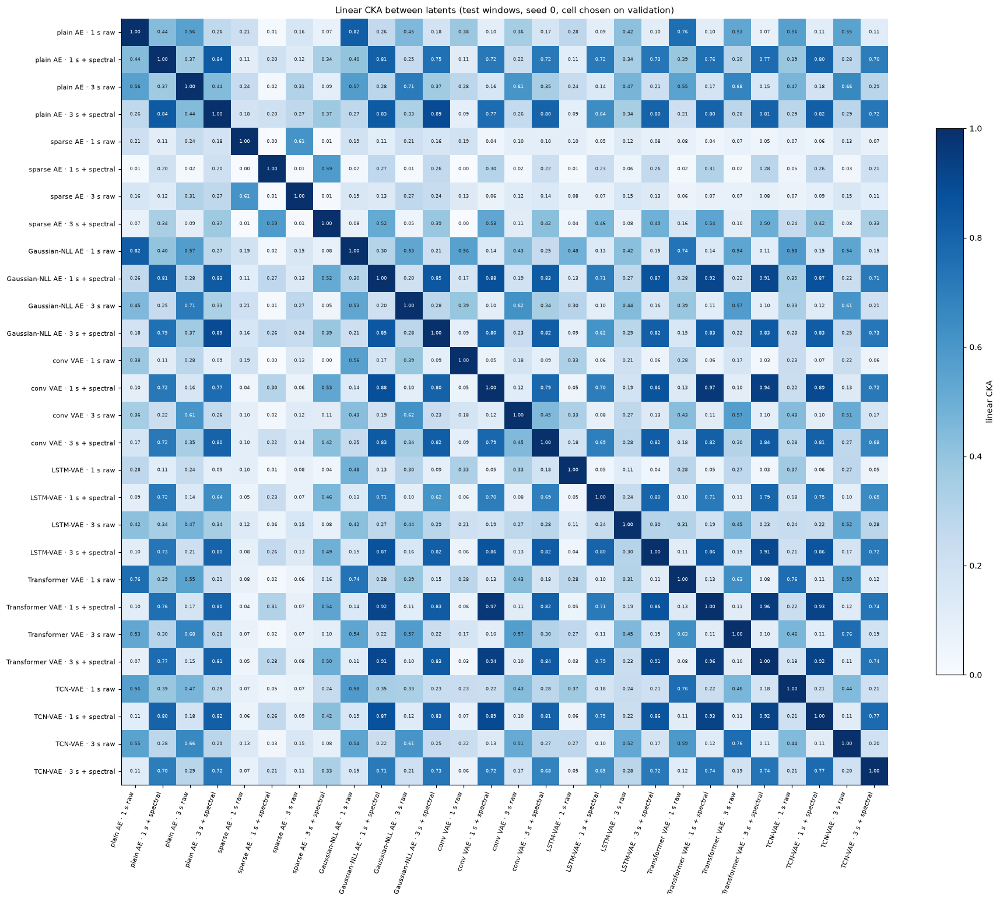

mean CKA, same model type on different inputs: 0.33; same input, different model types: 0.55


In [26]:
rng_cka = np.random.default_rng(0)
first_run = with_val.iloc[0].run
common_keys = test_labels[first_run][pd.MultiIndex.from_frame(test_labels[first_run][['rec', 'end']]).isin(COMMON)][['rec', 'end']]
sample_keys = common_keys.iloc[np.sort(rng_cka.choice(len(common_keys), 4000, replace = False))].reset_index(drop = True)
latents = {}
for (tp, inp), m in full['model'].items():
    if not isinstance(m, str):
        continue
    r = with_val[with_val['model'] == m].sort_values('seed').iloc[0]           # seed 0 when it exists
    lab = test_labels[r.run]
    z_test = ns.get_array(exports[r.run], 'z')[~exports[r.run]['is_train']]      # read from disk
    idx = lab[['rec', 'end']].reset_index().merge(sample_keys, on = ['rec', 'end'], how = 'right')['index'].to_numpy()
    latents[f'{tp} · {inp}'] = z_test[idx]
names_cka = list(latents)
cka = pd.DataFrame([[ns.get_linear_cka(latents[a], latents[b]) for b in names_cka] for a in names_cka], index = names_cka, columns = names_cka)
fig, ax = plt.subplots(figsize = (0.5 * len(names_cka) + 3, 0.5 * len(names_cka) + 1.5))
im = ax.imshow(cka.to_numpy(), cmap = 'Blues', vmin = 0, vmax = 1)
for r_ in range(len(names_cka)):
    for k in range(len(names_cka)):
        ax.text(k, r_, f'{cka.iat[r_, k]:.2f}', ha = 'center', va = 'center', fontsize = 5.5, color = 'white' if cka.iat[r_, k] > .6 else '#222')
ax.set_xticks(range(len(names_cka)), names_cka, rotation = 70, ha = 'right', fontsize = 7); ax.set_yticks(range(len(names_cka)), names_cka, fontsize = 7)
ax.set_title('Linear CKA between latents (test windows, seed 0, cell chosen on validation)', fontsize = 10)
fig.colorbar(im, ax = ax, shrink = .6, label = 'linear CKA'); plt.tight_layout(); fig.savefig(FIG_DIR / '05_full_cka.png', dpi = 160); plt.show()
same_type = [cka.loc[a, b] for a in names_cka for b in names_cka if a < b and a.split(' · ')[0] == b.split(' · ')[0]]
same_input = [cka.loc[a, b] for a in names_cka for b in names_cka if a < b and a.split(' · ')[1] == b.split(' · ')[1]]
print(f'mean CKA, same model type on different inputs: {np.mean(same_type):.2f}; same input, different model types: {np.mean(same_input):.2f}')

### 9.5 What this shows

- **3 s raw is the best input for every model type.** Test AUROC for unfamiliar windows: plain AE 0.950, sparse AE
  0.907, Gaussian-NLL AE 0.943, conv VAE 0.939, LSTM-VAE 0.963, Transformer VAE 0.949, TCN-VAE 0.950 (0.985 to 0.995 for
  the OOD-dangerous tasks, except the sparse AE; the TCN-VAE's 0.995 is the highest). The best detector of the study is the **LSTM-VAE on 3 s raw** (β 1, fixed variance, LOF):
  0.963 ± 0.004 and 0.993 ± 0.003, flagging 77% of unfamiliar and 88% of dangerous windows at 0.8% false alarms.
- **The spectral features hurt detection.** Adding them lowers the chosen AUROC at 3 s by 0.03 to 0.10 for every model
  type, and at 1 s for every type but the LSTM-VAE and the TCN-VAE (+0.01, +0.02). Lengthening the window helps: 1 s to 3 s raw adds 0.04 to
  0.10 (the LSTM-VAE gains most, +0.10, from 0.859, ahead of only the sparse AE at 1 s, to the best).
- **Why, latent to latent:** the spectral features make every architecture learn nearly the same latent. Mean linear CKA
  is 0.68 between latents that both have the spectral input, 0.37 between latents that both have raw input, 0.15 across
  the two. The seven constant channels, which carry each person's rhythm, dominate the code and crowd out the movement's
  shape, which is what separates unfamiliar movement. The same input makes model types alike (mean CKA 0.55) more than the
  same model type makes inputs alike (0.33): the input matters more than the architecture.
- **Metric by metric** (9.1): LOF on the latent has the best test AUROC on 23 of the 28 set-ups. The exceptions are the
  four VAEs (conv, LSTM, Transformer, TCN) on 1 s + spectral, where the decoder likelihood wins (negative ELBO 0.87 to 0.88),
  and the conv VAE on 1 s raw, where the downward KL at β 128 wins (0.90 against 0.88). On the LSTM-VAE's 3 s raw latent
  the cheap scores work too: Mahalanobis distance 0.950 (0.997 for dangerous tasks; one matrix-vector product per window)
  and the posterior variance 0.897 (higher = unfamiliar), the VAE uncertainty signal the conv VAE never gave (its
  posterior variance reaches 0.70 to 0.80 and points downward on three of its four inputs). The decoder NLL and negative
  ELBO reach 0.85 to 0.89 with the spectral input and 0.59 to 0.72 without (reconstruction error 0.74 to 0.80 and 0.56
  to 0.71): an unfamiliar rhythm in the constant spectral channels cannot be reconstructed.
- **The spectral features, not the window, set the KL's direction.** With fixed variance the KL reads downward (lower =
  unfamiliar) on raw input for every architecture, strongest at β 128 (conv 0.90 on 1 s and 0.87 on 3 s raw, Transformer
  0.89 on 3 s raw), and upward wherever the spectral features are present. β 128 collapses the LSTM-VAE's posterior on
  both raw inputs and the Transformer's on 1 s raw (KL zero; notebooks 03 and 04), so their entries there come from an
  empty code.
- **Per movement** (9.3): every 3 s raw model except the sparse AE flags 90 to 100% of the dangerous movements, at a
  median of 0 to 0.27 s, and alarms on 4 to 6% of familiar movements.

## 10. Adding a model or a score

- **A new model** (another seed, variant, or family such as a VAE): train it so that its run folder under
  `notebooks/nature/model_exploration/runs/` (any subfolder) holds `config.json`, `summary.json` and `latents.npz`
  with the arrays `rows`, `rec`, `end`, `z`, `recon_mse` and `is_train`, as `ml/nature/awareness/train_ae.py` writes
  them, and with its folder named `<stem>_s<seed>`. Rerun this notebook: the run is discovered, scored and added to
  every table and figure. Its `config.json` needs `inputs` (the window table its `rows` index); `variant`,
  `sparsity_weight` and `latent` are used for the label when present, otherwise the stem is.
- **A new score**: add a function `(export, fit_idx, cal_idx) -> (calibration scores, test scores)` to `SCORES` in
  `_novelty_scores.py`, larger meaning more unfamiliar. It is evaluated with the same protocol.
- If a new model exports a different set of test windows, every model is compared on the windows all of them share;
  the count is printed in section 1.
- **A native score**: add `name: (families or None, function(fit part, [parts]) -> [scores])` to `NATIVE` in
  `_novelty_scores.py`; each part is a dict of the export's arrays (`z`, `recon_mse`, and for a VAE `logvar`, `nll`,
  `kl`). Section 7 orients, thresholds and scores it like the others.

## 11. What this shows

**For the awareness pipeline**

- **Detect on 3 s raw windows, without the spectral features, with a sequence VAE.** The LSTM-VAE (β 1, LOF or, for an
  embedded controller, Mahalanobis distance on its latent) is the best alarm found: it flags every dangerous movement,
  half at its first window, at a familiar false-switch rate (6%) close to the 1 s autoencoders' (5 to 6%; section 9).
  Keep the spectral features for the regime classifier, where they separate task families (notebooks 02 and 03 of data
  exploration), not for novelty detection.

- **Pass several native scores downstream, chosen by input.** At high β with fixed variance the KL is a strong,
  seed-stable, inverted novelty signal on raw windows (conv VAE 0.90 on 1 s, Transformer VAE 0.89 on 3 s raw); on the
  LSTM-VAE's 3 s raw latent the posterior variance also works (0.897, higher = unfamiliar); with the spectral input the
  likelihood does (0.85 to 0.89). The regime classifier should take several native scores, since they combine (7.4), and
  be tested on held-out tasks.

- **Use LOF on a dense latent as the novelty baseline.** On 3 s raw windows it is the best score for every model type
  (section 9); the 1 s latents remain the choice if 2 s less history matters. Compare later models against the 3 s raw
  Gaussian-NLL control (0.943) and the LSTM-VAE (0.963).
- **Do not feed the sparse latents to LOF.** If their novelty units are used, score them directly (their activity
  against training windows) as a separate score in `SCORES`.
- **Set the operating point per wearer, and choose the false-alarm target as a controller decision.** Section 6: a
  threshold set on four held-out people misses its false-alarm target by about a factor of two on four others, and
  recall at matched false alarms is bounded by the ranking, not by the rule. Run the vanilla 1 s latent through 16
  principal components, and calibrate the threshold on a short familiar-walking bout of the wearer.
- **Quiet, posture-driven movement was the first latents' blind spot.** Standing poses and the ball toss looked familiar
  to every 1 s and 3 s + spectral latent, the same failure the ankle paper reported for standing. The 3 s raw VAEs close
  that gap for the dangerous tasks (every ball-toss bout flagged, half at its first window; section 8), and the
  LSTM-VAE's posterior is widest on exactly these quiet tasks (notebook 03). For the rest, a regime classifier
  (notebook 06) or posture features such as thigh pitch are the candidates.

**Limits**

- Sections 3 to 5 compare models on the test participants; section 6 chooses the representation and the threshold on
  the validation participants and reports test once, but the model ranking of sections 3 to 5 was still read off test.
- k = 20 follows the ankle paper and was not tuned; the 99.5th-percentile rule is replaced in section 6 by a
  validation false-alarm target. The 75 / 25 fit and calibration split of the exported training windows is fixed.
- Unfamiliar includes near-familiar tasks (curbs, obstacle and dynamic walking, walking backwards); flagging them
  rarely may be acceptable, which is why results are given per task.
- Windows are scored one by one, with the 0.5 s causal median before the threshold; detection delay is measured per
  movement in section 8, from each bout's first scored window.